<a href="https://colab.research.google.com/github/pattygirl665-lab/MA289-Neural-Network-Word-Embedding/blob/main/MA289_PyTorch_FFNN_to_Embeddings_with_Corpus_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MA289 — PyTorch: From Feed-Forward Neural Networks to Embeddings

This notebook is a concise bridge from the basic feed-forward neural-network lesson to the MA289 word-embedding competition.

## Running idea

We will first review the **syntax of PyTorch** with a tiny numerical FFNN, then reuse the same training pattern for a small token/context problem:

**center token → embedding → linear layer → context-token prediction**

The toy language data are intentionally small so that every part can be inspected and changed.

### Main ideas

1. Tensors and shapes
2. `nn.Module` and the `forward()` method
3. Loss functions and optimizers
4. Mini-batches and `DataLoader`
5. The training loop
6. Epochs, learning rate, batch size, and reproducibility
7. Token indexing
8. `nn.Embedding`
9. Cross-entropy context prediction
10. Extracting and comparing learned embeddings
11. Bridge to the MA289 Kaggle project

## 1. Imports and reproducibility

In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 289

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1+cpu
Device: cpu


## 2. PyTorch tensors

A **tensor** is PyTorch's basic numerical object.

Think of it as a NumPy array that can also participate in automatic differentiation and GPU computation.

Always check:

- shape
- dtype
- device

In [ ]:
x = torch.tensor(
    [[1.0, 2.0],
     [3.0, 4.0]]
)

print(x)
print("shape:", x.shape)
print("dtype:", x.dtype)
print("device:", x.device)

tensor([[1., 2.],
        [3., 4.]])
shape: torch.Size([2, 2])
dtype: torch.float32
device: cpu


## 3. A tiny feed-forward layer

A linear layer computes

\[
z = Wx + b
\]

PyTorch stores \(W\) and \(b\) as trainable parameters.

In [ ]:
layer = nn.Linear(
    in_features=2,
    out_features=3
)

z = layer(x)

print("Input shape :", x.shape)
print("Output shape:", z.shape)

print("\nWeight shape:", layer.weight.shape)
print("Bias shape  :", layer.bias.shape)

Input shape : torch.Size([2, 2])
Output shape: torch.Size([2, 3])

Weight shape: torch.Size([3, 2])
Bias shape  : torch.Size([3])


## 4. A minimal feed-forward neural network

PyTorch models usually inherit from `nn.Module`.

The `forward()` method describes the sequence of computations.

Here:

**2 inputs → hidden layer → ReLU → 1 output**

In [ ]:
class TinyFFNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Linear(2, 4)
        self.hidden2 = nn.Linear(4, 100)
        self.output = nn.Linear(100, 1)

    def forward(self, x):

        h2 = torch.sigmoid(
            self.hidden(x)
        )

        h = torch.relu(
            self.hidden2(h2)
        )

        y = self.output(h)

        return y


ffnn = TinyFFNN()

print(ffnn)

TinyFFNN(
  (hidden): Linear(in_features=2, out_features=4, bias=True)
  (hidden2): Linear(in_features=4, out_features=100, bias=True)
  (output): Linear(in_features=100, out_features=1, bias=True)
)


## 5. Forward pass

Calling `model(x)` automatically calls the model's `forward()` method.

The forward pass produces predictions.

In [ ]:
X_demo = torch.tensor(
    [[0.0, 0.0],
     [0.0, 1.0],
     [1.0, 0.0],
     [1.0, 1.0]]
)

with torch.no_grad():
    y_demo = ffnn(X_demo)

print(y_demo)
print("shape:", y_demo.shape)

tensor([[-0.0685],
        [-0.0646],
        [-0.0751],
        [-0.0677]])
shape: torch.Size([4, 1])


## 6. Loss + optimizer + backpropagation

The standard PyTorch training cycle is:

**forward pass → loss → backpropagation → parameter update**

The core syntax is:

```python
optimizer.zero_grad()
pred = model(x)
loss = criterion(pred, y)
loss.backward()
optimizer.step()
```

That is the same gradient-descent logic from the FFNN lesson.

In [ ]:
# A tiny regression target just to illustrate syntax.
y_target = torch.tensor(
    [[0.0],
     [1.0],
     [1.0],
     [2.0]]
)

model_demo = TinyFFNN()

criterion_demo = nn.MSELoss()

optimizer_demo = torch.optim.Adam(
    model_demo.parameters(),
    lr=0.01
)

optimizer_demo.zero_grad()

pred = model_demo(X_demo)

loss = criterion_demo(
    pred,
    y_target
)

loss.backward()

optimizer_demo.step()

print("One-step loss:", float(loss))

One-step loss: 0.9622721672058105


/tmp/ipykernel_937/1664274967.py:31: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  print("One-step loss:", float(loss))


# Part II — Running Token / Embedding Example

We now use the **same PyTorch pattern** for language.

The toy corpus is small and interpretable. You can directly edit the sentences and rerun the notebook.

## 7. Build a tiny text corpus

In [ ]:
sentences = [
    "dog chased ball",
    "cat chased ball",
    "dog ate food",
    "cat ate food",
    "student studies math",
    "cadet studies math",
    "student learns ai",
    "cadet learns ai",
]

for sentence in sentences:
    print(sentence)

dog chased ball
cat chased ball
dog ate food
cat ate food
student studies math
cadet studies math
student learns ai
cadet learns ai


## 8. Create center/context examples

For a context window of 1, the sentence

`dog chased ball`

creates pairs such as:

- `dog → chased`
- `chased → dog`
- `chased → ball`
- `ball → chased`

The model receives the **center token** and tries to predict a nearby **context token**.

In [ ]:
CONTEXT_WINDOW = 1

def make_pairs(sentences, window=1):

    pairs = []

    for sentence in sentences:

        tokens = sentence.split()

        for i, center in enumerate(tokens):

            left = max(
                0,
                i - window
            )

            right = min(
                len(tokens),
                i + window + 1
            )

            for j in range(left, right):

                if i != j:
                    pairs.append(
                        (center, tokens[j])
                    )

    return pairs


pairs = make_pairs(
    sentences,
    window=CONTEXT_WINDOW
)

pairs_df = pd.DataFrame(
    pairs,
    columns=[
        "center_token",
        "context_token"
    ]
)

display(pairs_df.head(12))

print("Number of training pairs:", len(pairs_df))

,center_token,context_token
0,dog,chased
1,chased,dog
2,chased,ball
3,ball,chased
4,cat,chased
5,chased,cat
6,chased,ball
7,ball,chased
8,dog,ate
9,ate,dog


Number of training pairs: 32


## 9. Token strings must become integer IDs

A neural network cannot multiply a matrix by the string `"dog"`.

We assign each unique token an integer index.

The integer is an **ID**, not a measurement.

In [ ]:
vocab = sorted(
    set(pairs_df["center_token"])
    | set(pairs_df["context_token"])
)

token_to_idx = {
    token: i
    for i, token in enumerate(vocab)
}

idx_to_token = {
    i: token
    for token, i in token_to_idx.items()
}

print("Vocabulary size:", len(vocab))

for token in vocab:
    print(
        f"{token:10s} -> "
        f"{token_to_idx[token]}"
    )

Vocabulary size: 12
ai         -> 0
ate        -> 1
ball       -> 2
cadet      -> 3
cat        -> 4
chased     -> 5
dog        -> 6
food       -> 7
learns     -> 8
math       -> 9
student    -> 10
studies    -> 11


## 10. Integer IDs use `torch.long`

Embedding layers use token IDs as lookup indices.

Therefore the input tensor must use integer type `torch.long`.

In [ ]:
center_ids = torch.tensor(
    pairs_df["center_token"]
    .map(token_to_idx)
    .to_numpy(),
    dtype=torch.long
)

context_ids = torch.tensor(
    pairs_df["context_token"]
    .map(token_to_idx)
    .to_numpy(),
    dtype=torch.long
)

print(center_ids[:10])
print("dtype:", center_ids.dtype)
print("shape:", center_ids.shape)

tensor([6, 5, 5, 2, 4, 5, 5, 2, 6, 1])
dtype: torch.int64
shape: torch.Size([32])


## 11. `nn.Embedding` is a trainable lookup table

If:

- vocabulary size = \(V\)
- embedding dimension = \(d\)

then:

\[
E \in \mathbb{R}^{V \times d}
\]

Each token ID selects one row of \(E\).

For the toy example, we begin with a very small embedding dimension so it is easy to inspect.

In [ ]:
V = len(vocab)
EMBED_DIM = 4

embedding_demo = nn.Embedding(
    num_embeddings=V,
    embedding_dim=EMBED_DIM
)

example_ids = torch.tensor(
    [
        token_to_idx["dog"],
        token_to_idx["cat"],
        token_to_idx["math"]
    ],
    dtype=torch.long
)

vectors = embedding_demo(
    example_ids
)

print("Embedding matrix shape:",
      embedding_demo.weight.shape)

print("\nSelected vectors:")
print(vectors)

Embedding matrix shape: torch.Size([12, 4])

Selected vectors:
tensor([[-0.1187,  0.4339, -0.1872, -0.3636],
        [ 0.0397, -0.3722,  0.1815, -0.1546],
        [-0.4294, -0.0386, -1.5992,  0.7492]], grad_fn=<EmbeddingBackward0>)


Before training, the embedding coordinates are essentially arbitrary.

Training gives the space structure.

## 12. Build the embedding FFNN

The baseline architecture is:

**center token ID → embedding → linear output → context-token logits**

There is one output logit for every possible context token.

In [ ]:
class EmbeddingFFNN(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=4
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        self.output = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, token_ids):

        e = self.embedding(
            token_ids
        )

        logits = self.output(
            e
        )

        return logits


model = EmbeddingFFNN(
    vocab_size=V,
    embedding_dim=EMBED_DIM
).to(DEVICE)

print(model)

EmbeddingFFNN(
  (embedding): Embedding(12, 4)
  (output): Linear(in_features=4, out_features=12, bias=True)
)


## 13. Mini-batches and `DataLoader`

Training one observation at a time is inefficient.

A `DataLoader` groups observations into mini-batches.

### Batch size tradeoff

- smaller batch: noisier gradients, more updates
- larger batch: smoother gradients, fewer updates
- very large batches can use more memory
- there is no universally best batch size

For this tiny example, use a small batch so the behavior is easy to inspect.

In [ ]:
BATCH_SIZE = 8

dataset = TensorDataset(
    center_ids,
    context_ids
)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

xb, yb = next(
    iter(loader)
)

print("center batch shape :", xb.shape)
print("context batch shape:", yb.shape)

print("\ncenter IDs:")
print(xb)

center batch shape : torch.Size([8])
context batch shape: torch.Size([8])

center IDs:
tensor([ 8,  3,  8,  0,  2, 10,  4,  8])


## 14. Check dimensions before training

For batch size \(B\), embedding dimension \(d\), and vocabulary size \(V\):

- input IDs: `(B,)`
- embeddings: `(B, d)`
- logits: `(B, V)`
- targets: `(B,)`

Checking shapes is one of the best neural-network debugging habits.

In [ ]:
xb = xb.to(DEVICE)
yb = yb.to(DEVICE)

with torch.no_grad():

    e_batch = model.embedding(
        xb
    )

    logits = model(
        xb
    )

print("IDs       :", xb.shape)
print("Embeddings:", e_batch.shape)
print("Logits    :", logits.shape)
print("Targets   :", yb.shape)

IDs       : torch.Size([8])
Embeddings: torch.Size([8, 4])
Logits    : torch.Size([8, 12])
Targets   : torch.Size([8])


## 15. Why cross-entropy?

Each center token is used to predict **one context-token class**.

The network outputs raw logits for all \(V\) possible classes.

Use:

```python
nn.CrossEntropyLoss()
```

Important:

- give cross-entropy **raw logits**
- do **not** manually apply softmax first
- target labels are integer class IDs

In [ ]:
criterion = nn.CrossEntropyLoss()

with torch.no_grad():

    logits = model(
        xb
    )

    example_loss = criterion(
        logits,
        yb
    )

print(
    "Example batch cross-entropy:",
    float(example_loss)
)

Example batch cross-entropy: 2.4549708366394043


## 16. Learning rate

The learning rate controls the size of each optimizer update.

Too large:
- training can oscillate or diverge

Too small:
- training may improve very slowly

A useful first experiment is often an order-of-magnitude comparison such as:

`0.1`, `0.01`, `0.001`

In [ ]:
LEARNING_RATE = 0.03

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.03
    maximize: False
    weight_decay: 0
)


## 17. Epochs

One **epoch** means one full pass through the training data.

Too few epochs:
- undertraining

Too many epochs:
- possible overfitting
- unnecessary computation

Always inspect the loss rather than selecting epochs blindly.

In [ ]:
EPOCHS = 80

history = []

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0.0
    total_n = 0

    for xb, yb in loader:

        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        logits = model(
            xb
        )

        loss = criterion(
            logits,
            yb
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item()
            * len(xb)
        )

        total_n += len(xb)

    mean_loss = (
        total_loss / total_n
    )

    history.append(
        mean_loss
    )

    if (
        epoch == 0
        or (epoch + 1) % 10 == 0
    ):
        print(
            f"Epoch {epoch+1:3d} | "
            f"loss={mean_loss:.4f}"
        )

Epoch   1 | loss=2.6303
Epoch  10 | loss=1.3346
Epoch  20 | loss=0.8054
Epoch  30 | loss=0.7428
Epoch  40 | loss=0.7322
Epoch  50 | loss=0.7228
Epoch  60 | loss=0.7120
Epoch  70 | loss=0.7215
Epoch  80 | loss=0.7206


## 18. Plot training loss

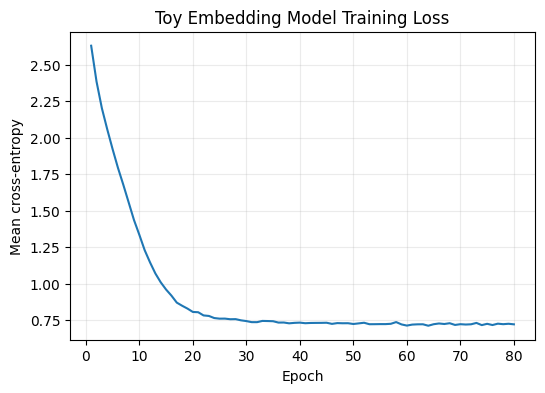

In [ ]:
plt.figure(figsize=(6, 4))

plt.plot(
    range(1, len(history) + 1),
    history
)

plt.xlabel("Epoch")
plt.ylabel("Mean cross-entropy")
plt.title("Toy Embedding Model Training Loss")
plt.grid(alpha=0.25)
plt.show()

## 19. Extract the learned embedding matrix

The context-prediction task created the learning signal.

The representation we care about is the learned embedding matrix.

In [ ]:
model.eval()

with torch.no_grad():

    E = (
        model.embedding
        .weight
        .detach()
        .cpu()
    )

print("Embedding matrix shape:", E.shape)

embedding_table = pd.DataFrame(
    E.numpy(),
    index=vocab,
    columns=[
        f"dim_{i+1}"
        for i in range(EMBED_DIM)
    ]
)

display(
    embedding_table.round(3)
)

Embedding matrix shape: torch.Size([12, 4])


,dim_1,dim_2,dim_3,dim_4
ai,2.731,-2.666,0.938,-0.206
ate,-1.587,1.837,1.474,-1.368
ball,0.407,-1.630,-2.233,2.380
cadet,1.643,-0.688,2.403,0.655
cat,-0.205,-1.399,-2.804,0.017
chased,-2.875,1.525,-0.881,0.833
dog,-0.744,-2.649,-1.747,0.439
food,-1.193,-1.682,-1.762,-2.060
learns,2.041,3.265,-2.445,0.838
math,2.554,1.579,1.594,2.537


## 20. Cosine similarity

Embedding coordinates themselves are not usually the main object of interest.

We care about **relative geometry**.

Cosine similarity compares the directions of two vectors.

In [ ]:
E_norm = E / E.norm(
    dim=1,
    keepdim=True
).clamp_min(1e-12)

def cosine_similarity(
    token_a,
    token_b
):

    i = token_to_idx[token_a]
    j = token_to_idx[token_b]

    return float(
        torch.dot(
            E_norm[i],
            E_norm[j]
        )
    )


examples = [
    ("dog", "cat"),
    ("student", "cadet"),
    ("math", "ai"),
    ("dog", "math"),
]

for a, b in examples:

    print(
        f"{a:8s} vs {b:8s}: "
        f"{cosine_similarity(a, b):.3f}"
    )

dog      vs cat     : 0.849
student  vs cadet   : 0.995
math     vs ai      : 0.224
dog      vs math    : -0.556


Because the corpus is tiny, do not expect perfect semantic structure.

The purpose is to see how the **training objective creates geometry**.

## 21. Nearest neighbors

In [ ]:
def nearest_neighbors(
    token,
    k=4
):

    idx = token_to_idx[token]

    sims = (
        E_norm
        @ E_norm[idx]
    )

    order = torch.argsort(
        sims,
        descending=True
    )

    rows = []

    for j in order.tolist():

        if j == idx:
            continue

        rows.append({
            "token": idx_to_token[j],
            "cosine_similarity":
                float(sims[j])
        })

        if len(rows) == k:
            break

    return pd.DataFrame(rows)


display(
    nearest_neighbors(
        "student",
        k=4
    )
)

display(
    nearest_neighbors(
        "dog",
        k=4
    )
)

,token,cosine_similarity
0,cadet,0.995147
1,ai,0.660703
2,math,0.626195
3,ate,-0.034645


,token,cosine_similarity
0,cat,0.848643
1,ball,0.742461
2,food,0.670910
3,ai,0.255049


## 22. Practical training considerations

These are the first knobs to understand.

| Choice | What it controls |
|---|---|
| Embedding dimension | capacity of each token representation |
| Batch size | examples per optimizer update |
| Learning rate | size of optimizer steps |
| Epochs | number of passes through training data |
| Optimizer | rule used to update parameters |
| Context window | what counts as a nearby word |
| Hidden layers | additional nonlinear modeling capacity |
| Seed | reproducibility of initialization and shuffling |

Do not change every setting at once. Make controlled comparisons.

## 23. A reusable experiment function

This cell lets you change a few important settings and compare final training loss.

Because this toy corpus is tiny, results can vary noticeably by configuration.

In [ ]:
def train_toy_model(
    embedding_dim=4,
    batch_size=8,
    learning_rate=0.03,
    epochs=60,
    seed=289
):

    torch.manual_seed(seed)

    model = EmbeddingFFNN(
        vocab_size=V,
        embedding_dim=embedding_dim
    ).to(DEVICE)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0.0
        total_n = 0

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            logits = model(xb)

            loss = criterion(
                logits,
                yb
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item()
                * len(xb)
            )

            total_n += len(xb)

        history.append(
            total_loss / total_n
        )

    return model, history

## 24. Example experiment: batch size

In [ ]:
batch_results = []

for batch_size in [
    2,
    8,
    32
]:

    m, h = train_toy_model(
        embedding_dim=4,
        batch_size=batch_size,
        learning_rate=0.03,
        epochs=60
    )

    batch_results.append({
        "batch_size":
            batch_size,
        "final_loss":
            h[-1]
    })

pd.DataFrame(
    batch_results
)

,batch_size,final_loss
0,2,0.797206
1,8,0.724443
2,32,0.725078


The smallest final training loss is not automatically the best model.

For a real project, use a validation set or leaderboard performance to judge generalization.

## 25. Example experiment: embedding dimension

In [ ]:
dim_results = []

for embedding_dim in [
    2,
    4,
    8
]:

    m, h = train_toy_model(
        embedding_dim=embedding_dim,
        batch_size=8,
        learning_rate=0.03,
        epochs=60
    )

    dim_results.append({
        "embedding_dim":
            embedding_dim,
        "parameters":
            sum(
                p.numel()
                for p in m.parameters()
            ),
        "final_loss":
            h[-1]
    })

pd.DataFrame(
    dim_results
)

,embedding_dim,parameters,final_loss
0,2,60,0.821517
1,4,108,0.724443
2,8,204,0.720508


A larger embedding has more capacity, but more capacity is not automatically better.

In the MA289 competition, compare:

- training behavior
- learned geometry
- Kaggle MSE
- model complexity

## 26. Optional extension: add a hidden feed-forward layer

The simple model is:

**token → embedding → output**

A natural FFNN extension is:

**token → embedding → dense → ReLU → output**

In [ ]:
class DeeperEmbeddingFFNN(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=4,
        hidden_dim=8
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        self.hidden = nn.Linear(
            embedding_dim,
            hidden_dim
        )

        self.output = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, token_ids):

        e = self.embedding(
            token_ids
        )

        h = torch.relu(
            self.hidden(e)
        )

        logits = self.output(
            h
        )

        return logits


deeper = DeeperEmbeddingFFNN(
    vocab_size=V,
    embedding_dim=4,
    hidden_dim=8
)

print(deeper)

print(
    "Number of parameters:",
    sum(
        p.numel()
        for p in deeper.parameters()
    )
)

DeeperEmbeddingFFNN(
  (embedding): Embedding(12, 4)
  (hidden): Linear(in_features=4, out_features=8, bias=True)
  (output): Linear(in_features=8, out_features=12, bias=True)
)
Number of parameters: 196


## 27. Bridge to the MA289 embedding competition

The real project uses the same pipeline at a larger scale:

**anonymous token → integer ID → embedding → context prediction → backpropagation → learned geometry → token-pair similarity**

The public competition files are:

- `train_corpus.txt`
- `context_train.csv`
- `test.csv`
- `sample_submission.csv`

Important differences from this toy example:

- about 900 anonymous tokens
- 300,000 center/context training pairs
- 1,200 test token pairs
- Kaggle evaluates similarity predictions with **Mean Squared Error**
- lower MSE is better

## 28. Suggested first competition experiments

Start simple.

1. Reproduce the baseline.
2. Change one major factor at a time.
3. Record the Kaggle MSE.
4. Explain why you made the change.

Good first experiments:

- embedding dimension
- batch size
- learning rate
- epochs
- optimizer
- context window
- hidden layer width
- regularization
- mapping from cosine similarity to the final \([0,1]\) prediction

# Exit Check

You should now be able to explain this chain:

**token string → integer ID → `nn.Embedding` → embedding vector → linear/FFNN output → cross-entropy → `loss.backward()` → optimizer update → learned embedding matrix → cosine similarity**

## Next conceptual step

This embedding gives each token one fixed vector.

It does **not** carry memory through an ordered sequence.

That limitation motivates:

**RNN → LSTM → encoder-decoder → attention → transformers**

---

# Part III — End-to-End Embedding Demonstration on a New Corpus

The competition uses anonymous tokens, so we cannot visually interpret the original word meanings.

To finish the lesson, we will repeat the same embedding idea on a **different, public corpus with visible English words**.

We will:

1. download the NLTK Reuters news corpus;
2. clean a manageable sample of the corpus;
3. build center/context pairs;
4. train the same simple `Embedding → Linear` model;
5. inspect nearest neighbors;
6. project the learned embedding space into two dimensions with PCA;
7. make a labeled visualization of groups of nearby words.

### Why Reuters?

Reuters is a collection of news articles. It contains repeated language about topics such as:

- markets
- banking
- trade
- oil
- companies
- government
- currencies
- commodities

Because words used in similar contexts receive similar training signals, we should see some of these words organize into nearby regions of the learned embedding space.

> This is a demonstration, not a production-quality language model. We deliberately keep the vocabulary, number of context pairs, embedding dimension, and number of epochs small enough to run comfortably in Google Colab.

## 29. Download a different public corpus

In [ ]:
!pip -q install nltk

In [ ]:
import nltk

nltk.download(
    "reuters",
    quiet=True
)

nltk.download(
    "stopwords",
    quiet=True
)

from nltk.corpus import reuters
from nltk.corpus import stopwords

print(
    "Reuters documents:",
    len(reuters.fileids())
)

print(
    "English stopwords loaded:",
    len(stopwords.words("english"))
)

Reuters documents: 10788
English stopwords loaded: 198


## 30. Clean a manageable sample

We will randomly select a subset of Reuters documents.

For this visualization we remove:

- punctuation;
- numbers;
- very short words;
- common stopwords such as `the`, `and`, and `of`.

Removing stopwords is **not required for embeddings in general**. We do it here only to make the final semantic visualization easier to interpret.

The random seed keeps the sample reproducible.

In [ ]:
from collections import Counter

CORPUS_SEED = 289
N_DOCUMENTS = 1400

rng = random.Random(
    CORPUS_SEED
)

all_fileids = list(
    reuters.fileids()
)

chosen_fileids = rng.sample(
    all_fileids,
    k=min(
        N_DOCUMENTS,
        len(all_fileids)
    )
)

STOP_WORDS = set(
    stopwords.words(
        "english"
    )
)

def clean_reuters_document(fileid):

    cleaned = []

    for word in reuters.words(
        fileids=[fileid]
    ):

        word = word.lower()

        if not word.isalpha():
            continue

        if len(word) < 3:
            continue

        if word in STOP_WORDS:
            continue

        cleaned.append(word)

    return cleaned


reuters_docs = [
    clean_reuters_document(fid)
    for fid in chosen_fileids
]

reuters_docs = [
    doc
    for doc in reuters_docs
    if len(doc) >= 5
]

print(
    "Documents retained:",
    len(reuters_docs)
)

print(
    "Total cleaned tokens:",
    f"{sum(len(doc) for doc in reuters_docs):,}"
)

print("\nExample cleaned document:")
print(
    reuters_docs[0][:40]
)

Documents retained: 1393
Total cleaned tokens: 102,849

Example cleaned document:
['old', 'stone', 'ostn', 'completes', 'acquisition', 'old', 'stone', 'corp', 'said', 'completed', 'previously', 'announced', 'acquisition', 'first', 'federal', 'savings', 'bank', 'north', 'carolina', 'shelby', 'savings', 'bank', 'common', 'stock', 'final', 'purchase', 'price', 'expected', 'seven', 'mln', 'mln', 'dlrs', 'based', 'exchange', 'common', 'stock', 'valued', 'times', 'book', 'value']


## 31. Build a small vocabulary

The complete Reuters corpus contains many words.

For a fast demonstration, keep only the most frequent words in our sampled documents.

This mirrors a common practical choice in NLP: extremely rare tokens provide little training signal and increase model size.

In [ ]:
REUTERS_VOCAB_SIZE = 800

reuters_counts = Counter()

for doc in reuters_docs:
    reuters_counts.update(doc)

reuters_vocab = [
    word
    for word, count
    in reuters_counts.most_common(
        REUTERS_VOCAB_SIZE
    )
]

reuters_word_to_idx = {
    word: i
    for i, word
    in enumerate(reuters_vocab)
}

reuters_idx_to_word = {
    i: word
    for word, i
    in reuters_word_to_idx.items()
}

print(
    "Vocabulary size:",
    len(reuters_vocab)
)

print("\nMost frequent retained words:")
print(
    reuters_counts.most_common(25)
)

Vocabulary size: 800

Most frequent retained words:
[('said', 3129), ('mln', 2308), ('dlrs', 1517), ('pct', 1184), ('cts', 1093), ('year', 927), ('net', 913), ('loss', 710), ('billion', 672), ('company', 575), ('shr', 565), ('inc', 548), ('would', 546), ('bank', 466), ('oil', 450), ('corp', 419), ('tonnes', 402), ('last', 398), ('share', 396), ('profit', 392), ('one', 361), ('stock', 348), ('market', 345), ('qtr', 333), ('two', 321)]


## 32. Create center/context pairs

We use the same learning task as before:

**center word → predict nearby context word**

The context window is 2 words on each side.

To keep training fast, we randomly retain at most 140,000 center/context pairs.

In [ ]:
REUTERS_WINDOW = 2
MAX_REUTERS_PAIRS = 140_000

all_reuters_pairs = []

for doc in reuters_docs:

    retained = [
        word
        for word in doc
        if word in reuters_word_to_idx
    ]

    for i, center in enumerate(
        retained
    ):

        left = max(
            0,
            i - REUTERS_WINDOW
        )

        right = min(
            len(retained),
            i + REUTERS_WINDOW + 1
        )

        for j in range(
            left,
            right
        ):

            if i != j:

                all_reuters_pairs.append(
                    (
                        reuters_word_to_idx[
                            center
                        ],
                        reuters_word_to_idx[
                            retained[j]
                        ]
                    )
                )

print(
    "Possible center/context pairs:",
    f"{len(all_reuters_pairs):,}"
)

pair_rng = np.random.default_rng(
    CORPUS_SEED
)

if len(all_reuters_pairs) > MAX_REUTERS_PAIRS:

    keep = pair_rng.choice(
        len(all_reuters_pairs),
        size=MAX_REUTERS_PAIRS,
        replace=False
    )

    reuters_pairs = [
        all_reuters_pairs[i]
        for i in keep
    ]

else:
    reuters_pairs = all_reuters_pairs

print(
    "Training pairs retained:",
    f"{len(reuters_pairs):,}"
)

print("\nFirst five integer pairs:")
print(
    reuters_pairs[:5]
)

print("\nSame pairs as words:")

for center_id, context_id in reuters_pairs[:5]:

    print(
        reuters_idx_to_word[
            center_id
        ],
        "->",
        reuters_idx_to_word[
            context_id
        ]
    )

Possible center/context pairs: 267,326
Training pairs retained: 140,000

First five integer pairs:
[(2, 0), (459, 82), (4, 1), (218, 439), (187, 362)]

Same pairs as words:
dlrs -> said
largest -> added
cts -> mln
annual -> raises
split -> adjusted


## 33. Convert the pairs to PyTorch tensors

This is the exact same tensor structure used earlier:

- center IDs are integer indices;
- context IDs are integer class labels;
- both use `torch.long`.

In [ ]:
reuters_center_ids = torch.tensor(
    [
        pair[0]
        for pair in reuters_pairs
    ],
    dtype=torch.long
)

reuters_context_ids = torch.tensor(
    [
        pair[1]
        for pair in reuters_pairs
    ],
    dtype=torch.long
)

print(
    "Center tensor:",
    reuters_center_ids.shape,
    reuters_center_ids.dtype
)

print(
    "Context tensor:",
    reuters_context_ids.shape,
    reuters_context_ids.dtype
)

Center tensor: torch.Size([140000]) torch.int64
Context tensor: torch.Size([140000]) torch.int64


## 34. Train the same simple embedding model

We intentionally use the same architecture:

**center word ID → `nn.Embedding` → `nn.Linear` → context-word logits**

The only major differences are:

- a larger vocabulary;
- more center/context pairs;
- a larger embedding dimension.

This reinforces the main idea: **the same simple neural-network mechanism can learn useful representations from a real corpus**.

In [ ]:
REUTERS_EMBED_DIM = 20
REUTERS_BATCH_SIZE = 2048
REUTERS_EPOCHS = 4
REUTERS_LR = 0.01

reuters_dataset = TensorDataset(
    reuters_center_ids,
    reuters_context_ids
)

reuters_loader = DataLoader(
    reuters_dataset,
    batch_size=REUTERS_BATCH_SIZE,
    shuffle=True
)


class ReutersEmbeddingFFNN(
    nn.Module
):

    def __init__(
        self,
        vocab_size,
        embedding_dim
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        self.output = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(
        self,
        token_ids
    ):

        e = self.embedding(
            token_ids
        )

        logits = self.output(
            e
        )

        return logits


reuters_model = ReutersEmbeddingFFNN(
    vocab_size=len(
        reuters_vocab
    ),
    embedding_dim=REUTERS_EMBED_DIM
).to(DEVICE)

reuters_criterion = (
    nn.CrossEntropyLoss()
)

reuters_optimizer = (
    torch.optim.Adam(
        reuters_model.parameters(),
        lr=REUTERS_LR
    )
)

print(reuters_model)
print("\nDevice:", DEVICE)

ReutersEmbeddingFFNN(
  (embedding): Embedding(800, 20)
  (output): Linear(in_features=20, out_features=800, bias=True)
)

Device: cpu


## 35. Train and watch the loss

The model again learns only by trying to predict nearby words.

If the mean cross-entropy decreases, the network is finding structure in the corpus.

In [ ]:
reuters_history = []

for epoch in range(
    REUTERS_EPOCHS
):

    reuters_model.train()

    total_loss = 0.0
    total_n = 0

    for xb, yb in reuters_loader:

        xb = xb.to(
            DEVICE
        )

        yb = yb.to(
            DEVICE
        )

        reuters_optimizer.zero_grad()

        logits = reuters_model(
            xb
        )

        loss = reuters_criterion(
            logits,
            yb
        )

        loss.backward()

        reuters_optimizer.step()

        total_loss += (
            loss.item()
            * len(xb)
        )

        total_n += len(xb)

    mean_loss = (
        total_loss
        / total_n
    )

    reuters_history.append(
        mean_loss
    )

    print(
        f"Epoch {epoch + 1:2d} | "
        f"mean cross-entropy = "
        f"{mean_loss:.4f}"
    )

Epoch  1 | mean cross-entropy = 6.3101
Epoch  2 | mean cross-entropy = 5.7767
Epoch  3 | mean cross-entropy = 5.6282
Epoch  4 | mean cross-entropy = 5.5494


## 36. Plot the Reuters training loss

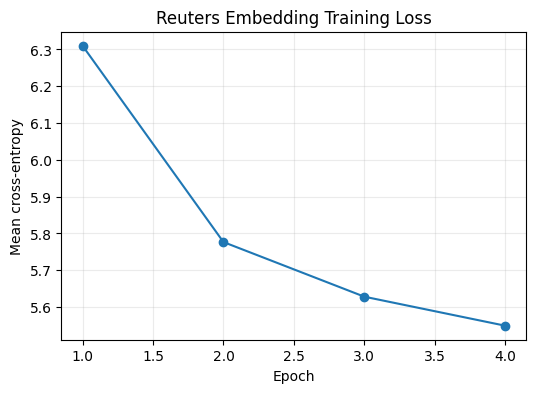

In [ ]:
plt.figure(
    figsize=(6, 4)
)

plt.plot(
    range(
        1,
        len(reuters_history) + 1
    ),
    reuters_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel(
    "Mean cross-entropy"
)
plt.title(
    "Reuters Embedding Training Loss"
)
plt.grid(
    alpha=0.25
)
plt.show()

## 37. Extract and normalize the learned word vectors

Each row of the embedding matrix now represents one visible Reuters word.

Normalizing the rows makes cosine similarity equal to a simple dot product.

In [ ]:
reuters_model.eval()

with torch.no_grad():

    R = (
        reuters_model.embedding
        .weight
        .detach()
        .cpu()
    )

R_norm = R / R.norm(
    dim=1,
    keepdim=True
).clamp_min(
    1e-12
)

print(
    "Embedding matrix shape:",
    R.shape
)

print(
    "Mean normalized row length:",
    R_norm.norm(
        dim=1
    ).mean().item()
)

Embedding matrix shape: torch.Size([800, 20])
Mean normalized row length: 1.0


## 38. Inspect nearest neighbors

This is the easiest way to see what the embedding has learned.

For a query word, we:

1. retrieve its embedding;
2. compute cosine similarity to every other word;
3. sort from most similar to least similar.

The exact neighbors will depend on the sampled Reuters documents and the stochastic training process, but related domain words should often appear near one another.

In [ ]:
def reuters_nearest_neighbors(
    word,
    k=8
):

    if word not in reuters_word_to_idx:

        return pd.DataFrame({
            "message": [
                f"{word!r} is not in "
                "the retained vocabulary."
            ]
        })

    idx = reuters_word_to_idx[
        word
    ]

    similarities = (
        R_norm
        @ R_norm[idx]
    )

    order = torch.argsort(
        similarities,
        descending=True
    )

    rows = []

    for j in order.tolist():

        if j == idx:
            continue

        rows.append({
            "word":
                reuters_idx_to_word[j],
            "cosine_similarity":
                float(
                    similarities[j]
                )
        })

        if len(rows) == k:
            break

    return pd.DataFrame(
        rows
    )


preferred_queries = [
    "market",
    "bank",
    "oil",
    "trade",
    "company",
    "government"
]

queries = [
    word
    for word in preferred_queries
    if word in reuters_word_to_idx
][:4]

print(
    "Query words:",
    queries
)

for word in queries:

    print(
        f"\nNearest neighbors for "
        f"{word!r}:"
    )

    display(
        reuters_nearest_neighbors(
            word,
            k=6
        )
    )

Query words: ['market', 'bank', 'oil', 'trade']

Nearest neighbors for 'market':


,word,cosine_similarity
0,used,0.703632
1,would,0.674776
2,commodity,0.654452
3,economic,0.623718
4,pacific,0.607788
5,wendy,0.599726



Nearest neighbors for 'bank':


,word,cosine_similarity
0,dealers,0.775848
1,saying,0.699935
2,french,0.693259
3,help,0.633761
4,firm,0.599532
5,burlington,0.563168



Nearest neighbors for 'oil':


,word,cosine_similarity
0,well,0.642382
1,expect,0.641294
2,opec,0.623657
3,low,0.619319
4,stocks,0.601489
5,gross,0.584467



Nearest neighbors for 'trade':


,word,cosine_similarity
0,conditions,0.613051
1,news,0.607611
2,move,0.568716
3,current,0.554693
4,recent,0.539332
5,reuters,0.538843


## 39. Build small word neighborhoods for visualization

For a readable figure, we will choose a few anchor words and the nearest learned neighbors around each anchor.

This is not a new training algorithm.

It is simply a way to select a small set of points from the already learned embedding space so that the geometry is easy to inspect.

Because Reuters is a news corpus, the visible groups will usually reflect **news and economic usage**, rather than general dictionary definitions.

In [ ]:
preferred_anchors = [
    "market",
    "bank",
    "oil",
    "trade",
    "company",
    "government",
    "gold",
    "dollar"
]

anchors = [
    word
    for word in preferred_anchors
    if word in reuters_word_to_idx
][:5]

if len(anchors) < 3:

    # Fallback: choose frequent words
    # if the preferred anchors are absent.
    anchors = [
        word
        for word in reuters_vocab[:100]
        if word not in STOP_WORDS
    ][:5]

print(
    "Visualization anchors:",
    anchors
)

words_to_plot = []
group_for_word = {}
used_words = set()

for anchor in anchors:

    if anchor not in used_words:

        words_to_plot.append(
            anchor
        )

        group_for_word[
            anchor
        ] = anchor

        used_words.add(
            anchor
        )

    neighbors = (
        reuters_nearest_neighbors(
            anchor,
            k=12
        )
    )

    if "word" not in neighbors.columns:
        continue

    added = 0

    for word in neighbors["word"]:

        if word in used_words:
            continue

        words_to_plot.append(
            word
        )

        group_for_word[
            word
        ] = anchor

        used_words.add(
            word
        )

        added += 1

        if added == 4:
            break

print(
    "Words selected for plot:",
    len(words_to_plot)
)

print(words_to_plot)

Visualization anchors: ['market', 'bank', 'oil', 'trade', 'company']
Words selected for plot: 25
['market', 'used', 'would', 'commodity', 'economic', 'bank', 'dealers', 'saying', 'french', 'help', 'oil', 'well', 'expect', 'opec', 'low', 'trade', 'conditions', 'news', 'move', 'current', 'company', 'final', 'stores', 'joint', 'manager']


## 40. Project the embedding space to two dimensions with PCA

The learned embeddings live in 20 dimensions.

Humans cannot directly view a 20-dimensional space, so we use **Principal Component Analysis**, or PCA, to project the vectors into two dimensions.

Important caution:

> PCA is only a visualization. Distances in the 2D picture are an approximation of the higher-dimensional embedding geometry.

Still, if the embedding has learned useful structure, nearby words often remain visibly grouped.

In [ ]:
from sklearn.decomposition import PCA

reuters_pca = PCA(
    n_components=2,
    random_state=CORPUS_SEED
)

R_2d = reuters_pca.fit_transform(
    R_norm.numpy()
)

plot_rows = []

for word in words_to_plot:

    idx = reuters_word_to_idx[
        word
    ]

    plot_rows.append({
        "word": word,
        "group":
            group_for_word[word],
        "x":
            R_2d[idx, 0],
        "y":
            R_2d[idx, 1]
    })

plot_df = pd.DataFrame(
    plot_rows
)

display(
    plot_df.head()
)

,word,group,x,y
0,market,market,0.063943,-0.149401
1,used,market,0.358514,-0.003162
2,would,market,0.165570,-0.027713
3,commodity,market,-0.020493,-0.627527
4,economic,market,0.046579,-0.057397


## 41. Labeled embedding-neighborhood visualization

Each label is an actual word from the Reuters corpus.

Words assigned to the same displayed group were selected because they are close to the same anchor word in the learned embedding space.

Look for:

- words from similar economic or news contexts appearing near one another;
- separate neighborhoods around different anchor words;
- overlap when a word is useful in several kinds of contexts.

This is the visual intuition behind an embedding:

**meaningful contextual relationships become geometric relationships between vectors.**

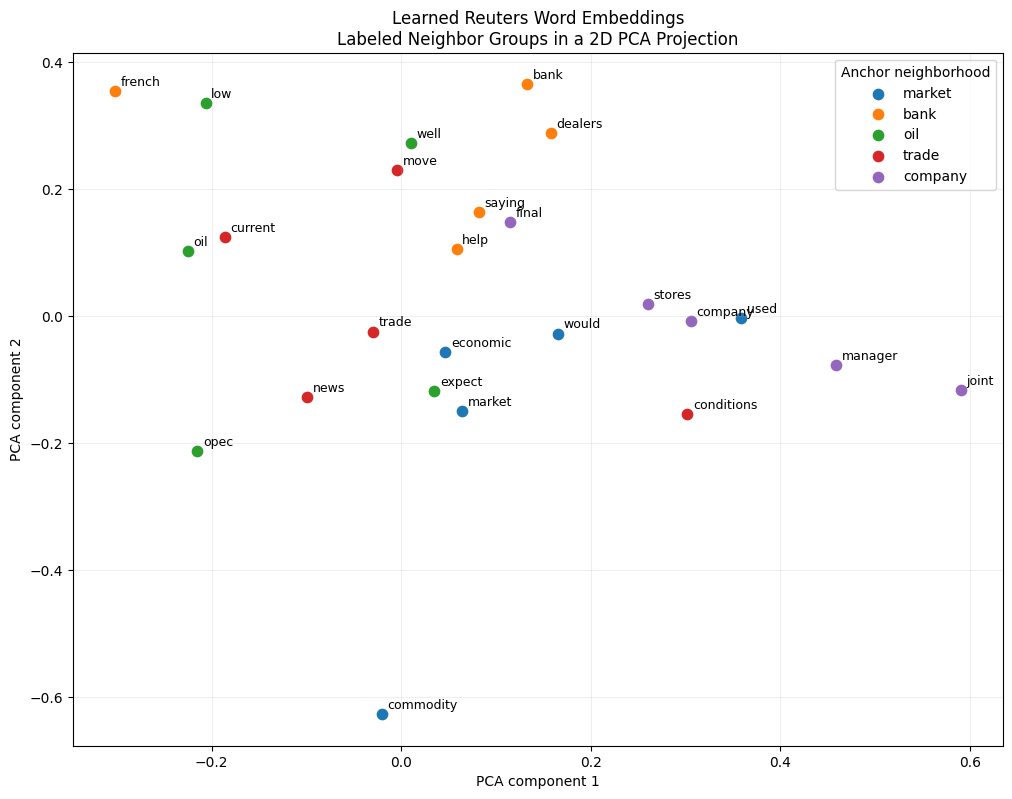

In [ ]:
plt.figure(
    figsize=(12, 9)
)

for anchor in anchors:

    group = plot_df[
        plot_df["group"]
        == anchor
    ]

    if len(group) == 0:
        continue

    plt.scatter(
        group["x"],
        group["y"],
        label=anchor,
        s=55
    )

    for _, row in group.iterrows():

        plt.annotate(
            row["word"],
            (
                row["x"],
                row["y"]
            ),
            fontsize=9,
            xytext=(4, 4),
            textcoords="offset points"
        )

plt.xlabel(
    "PCA component 1"
)

plt.ylabel(
    "PCA component 2"
)

plt.title(
    "Learned Reuters Word Embeddings\n"
    "Labeled Neighbor Groups in a 2D PCA Projection"
)

plt.legend(
    title="Anchor neighborhood"
)

plt.grid(
    alpha=0.2
)

plt.show()

## 42. What this final picture demonstrates

The model was **never given definitions** of words such as `market`, `bank`, `oil`, or `trade`.

It received only center/context examples from real text.

During training:

1. words appearing in similar contexts generated similar prediction pressures;
2. backpropagation adjusted their embedding vectors;
3. repeated updates organized the embedding space;
4. related contextual patterns became nearby geometric patterns.

That is why embeddings are useful.

The numerical vector is not manually designed to mean anything.

Its usefulness **emerges from the prediction task**.

### Connection back to the competition

The MA289 competition hides the original words, but the learning mechanism is the same:

**anonymous token → context prediction → backpropagation → learned embedding geometry → token-pair similarity**

The Reuters example lets us see with readable labels what the competition model is learning with anonymous token IDs.

# Final Notebook Summary

We started with the syntax of a basic PyTorch feed-forward neural network and then extended exactly the same training logic to word embeddings.

The full progression was:

**tensor → `nn.Module` → forward pass → loss → `backward()` → optimizer step**

then:

**token → integer ID → `nn.Embedding` → context prediction → learned vector**

and finally:

**learned vectors → cosine similarity → nearest neighbors → 2D visualization**

The Reuters demonstration gives us a visible example of the core representation-learning idea that motivates the MA289 embedding competition.

The next conceptual limitation is that each token still receives one fixed vector.

That motivates sequence models:

**RNN → LSTM → encoder-decoder → attention → transformers**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

# Define the base path to your Google Drive folder
drive_folder_path = '/content/drive/MyDrive/Wu Colab Notebooks/Neural Network' # Updated folder path

# Load the datasets
try:
    train_df = pd.read_csv(f'{drive_folder_path}/context_train.csv')
    test_df = pd.read_csv(f'{drive_folder_path}/test.csv')
    sample_submission_df = pd.read_csv(f'{drive_folder_path}/sample_submission.csv')

    print('Data loaded successfully!')
    print('\nTrain DataFrame head:')
    display(train_df.head())
    print('\nTest DataFrame head:')
    display(test_df.head())
    print('\nSample Submission DataFrame head:')
    display(sample_submission_df.head())

except FileNotFoundError:
    print(f"Error: Make sure the path '{drive_folder_path}' is correct and the files are present.")
except Exception as e:
    print(f"An error occurred while loading files: {e}")

Data loaded successfully!

Train DataFrame head:


,center_token,context_token
0,tok_0255,tok_0099
1,tok_0777,tok_0455
2,tok_0512,tok_0468
3,tok_0022,tok_0242
4,tok_0681,tok_0584



Test DataFrame head:


,pair_id,token1,token2
0,pair_0001,tok_0491,tok_0759
1,pair_0002,tok_0132,tok_0182
2,pair_0003,tok_0062,tok_0474
3,pair_0004,tok_0141,tok_0243
4,pair_0005,tok_0594,tok_0843



Sample Submission DataFrame head:


,pair_id,similarity
0,pair_0001,0.5
1,pair_0002,0.5
2,pair_0003,0.5
3,pair_0004,0.5
4,pair_0005,0.5


### 1. Preprocess Competition Data and Setup Vocabulary

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Create vocabulary from all unique tokens in training and testing datasets
all_tokens = pd.concat([
    train_df['center_token'],
    train_df['context_token'],
    test_df['token1'],
    test_df['token2']
]).unique()

vocab = sorted(list(all_tokens))
token_to_idx = {token: i for i, token in enumerate(vocab)}
idx_to_token = {i: token for token, i in token_to_idx.items()}
VOCAB_SIZE = len(vocab)

print(f"Total unique tokens in vocabulary: {VOCAB_SIZE}")

# Map training data to integer indices
train_center_ids = torch.tensor(train_df['center_token'].map(token_to_idx).values, dtype=torch.long)
train_context_ids = torch.tensor(train_df['context_token'].map(token_to_idx).values, dtype=torch.long)


Total unique tokens in vocabulary: 900


### 2. Define Model and Train on Competition Dataset

In [ ]:
# Hyperparameters
EMBEDDING_DIM = 50
BATCH_SIZE = 1024
LEARNING_RATE = 0.01
EPOCHS = 10

train_dataset = TensorDataset(train_center_ids, train_context_ids)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

class CompetitionEmbeddingModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, token_ids):
        embeds = self.embedding(token_ids)
        logits = self.output(embeds)
        return logits

# Initialize model, loss and optimizer
comp_model = CompetitionEmbeddingModel(VOCAB_SIZE, EMBEDDING_DIM).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(comp_model.parameters(), lr=LEARNING_RATE)

# Training Loop
comp_model.train()
for epoch in range(EPOCHS):
    epoch_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer.zero_grad()
        logits = comp_model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * len(xb)

    mean_loss = epoch_loss / len(train_dataset)
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | Train Loss: {mean_loss:.4f}")


Epoch 01/10 | Train Loss: 5.5155
Epoch 02/10 | Train Loss: 5.2522
Epoch 03/10 | Train Loss: 5.2022
Epoch 04/10 | Train Loss: 5.1680
Epoch 05/10 | Train Loss: 5.1428
Epoch 06/10 | Train Loss: 5.1236
Epoch 07/10 | Train Loss: 5.1082
Epoch 08/10 | Train Loss: 5.0958
Epoch 09/10 | Train Loss: 5.0853
Epoch 10/10 | Train Loss: 5.0767


### 3. Compute Cosine Similarities and Generate Submission File

In [ ]:
# Extract learned embedding weight matrix
comp_model.eval()
with torch.no_grad():
    embeddings = comp_model.embedding.weight.detach().cpu()

# Normalize embeddings to easily calculate Cosine Similarity
embeddings_norm = embeddings / embeddings.norm(dim=1, keepdim=True).clamp_min(1e-12)

# Generate predictions for testing dataset
similarities = []
for _, row in test_df.iterrows():
    tok1, tok2 = row['token1'], row['token2']

    idx1 = token_to_idx[tok1]
    idx2 = token_to_idx[tok2]

    vec1 = embeddings_norm[idx1]
    vec2 = embeddings_norm[idx2]

    cos_sim = float(torch.dot(vec1, vec2))

    # Map cosine similarity [-1, 1] to target similarity range [0, 1] for submission
    scaled_sim = (cos_sim + 1.0) / 2.0
    similarities.append(scaled_sim)

# Create submission dataframe
submission = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': similarities
})

# Save submission file to Google Drive folder
submission_path = f"{drive_folder_path}/baseline_submission.csv"
submission.to_csv(submission_path, index=False)
print(f"Submission successfully saved to {submission_path}!")
display(submission.head())


Submission successfully saved to /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/baseline_submission.csv!


,pair_id,similarity
0,pair_0001,0.670798
1,pair_0002,0.511839
2,pair_0003,0.604809
3,pair_0004,0.595001
4,pair_0005,0.510213


### 4. Experimentation: Training a Deeper Embedding Network with Hidden Layer

In [ ]:
# Hyperparameters for the deeper model
DEEPER_EMBEDDING_DIM = 64
HIDDEN_DIM = 128
BATCH_SIZE_DEEPER = 1024
LEARNING_RATE_DEEPER = 0.005
EPOCHS_DEEPER = 12

class DeeperCompetitionEmbeddingModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.hidden = nn.Linear(embedding_dim, hidden_dim)
        self.output = nn.Linear(hidden_dim, vocab_size)

    def forward(self, token_ids):
        embeds = self.embedding(token_ids)
        h = torch.relu(self.hidden(embeds))
        logits = self.output(h)
        return logits

# Prepare data loaders
train_loader_deeper = DataLoader(train_dataset, batch_size=BATCH_SIZE_DEEPER, shuffle=True)

# Initialize Deeper model
deeper_comp_model = DeeperCompetitionEmbeddingModel(VOCAB_SIZE, DEEPER_EMBEDDING_DIM, HIDDEN_DIM).to(DEVICE)
criterion_deeper = nn.CrossEntropyLoss()
optimizer_deeper = torch.optim.Adam(deeper_comp_model.parameters(), lr=LEARNING_RATE_DEEPER)

# Training Loop
deeper_comp_model.train()
for epoch in range(EPOCHS_DEEPER):
    epoch_loss = 0.0
    for xb, yb in train_loader_deeper:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer_deeper.zero_grad()
        logits = deeper_comp_model(xb)
        loss = criterion_deeper(logits, yb)
        loss.backward()
        optimizer_deeper.step()

        epoch_loss += loss.item() * len(xb)

    mean_loss = epoch_loss / len(train_dataset)
    print(f"Epoch {epoch+1:02d}/{EPOCHS_DEEPER} | Train Loss: {mean_loss:.4f}")


Epoch 01/12 | Train Loss: 5.3624
Epoch 02/12 | Train Loss: 5.2186
Epoch 03/12 | Train Loss: 5.1678
Epoch 04/12 | Train Loss: 5.1330
Epoch 05/12 | Train Loss: 5.1073
Epoch 06/12 | Train Loss: 5.0870
Epoch 07/12 | Train Loss: 5.0702
Epoch 08/12 | Train Loss: 5.0564
Epoch 09/12 | Train Loss: 5.0446
Epoch 10/12 | Train Loss: 5.0346
Epoch 11/12 | Train Loss: 5.0255
Epoch 12/12 | Train Loss: 5.0179


### 5. Generate Submission 2 (Deeper Model Predictions)

In [ ]:
# Extract learned deeper embeddings
deeper_comp_model.eval()
with torch.no_grad():
    deeper_embeddings = deeper_comp_model.embedding.weight.detach().cpu()

# Normalize deeper embeddings
deeper_embeddings_norm = deeper_embeddings / deeper_embeddings.norm(dim=1, keepdim=True).clamp_min(1e-12)

# Generate predictions
deeper_similarities = []
for _, row in test_df.iterrows():
    tok1, tok2 = row['token1'], row['token2']

    idx1 = token_to_idx[tok1]
    idx2 = token_to_idx[tok2]

    vec1 = deeper_embeddings_norm[idx1]
    vec2 = deeper_embeddings_norm[idx2]

    cos_sim = float(torch.dot(vec1, vec2))
    scaled_sim = (cos_sim + 1.0) / 2.0
    deeper_similarities.append(scaled_sim)

# Create submission dataframe
deeper_submission = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': deeper_similarities
})

# Save deeper model submission file to Google Drive folder
deeper_submission_path = f"{drive_folder_path}/deeper_neural_network_submission.csv"
deeper_submission.to_csv(deeper_submission_path, index=False)
print(f"Deeper submission successfully saved to {deeper_submission_path}!")
display(deeper_submission.head())


Deeper submission successfully saved to /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/deeper_neural_network_submission.csv!


,pair_id,similarity
0,pair_0001,0.573790
1,pair_0002,0.510316
2,pair_0003,0.514788
3,pair_0004,0.530585
4,pair_0005,0.629628


### 6. Experiment 3: Overfitting the Deeper Model (Submission 3)

In [ ]:
EPOCHS_OVERFIT = 35
LEARNING_RATE_OVERFIT = 0.003

# Re-initialize deeper model to reset weights
overfit_model = DeeperCompetitionEmbeddingModel(VOCAB_SIZE, DEEPER_EMBEDDING_DIM, HIDDEN_DIM).to(DEVICE)
criterion_overfit = nn.CrossEntropyLoss()
optimizer_overfit = torch.optim.Adam(overfit_model.parameters(), lr=LEARNING_RATE_OVERFIT)

overfit_model.train()
for epoch in range(EPOCHS_OVERFIT):
    epoch_loss = 0.0
    for xb, yb in train_loader_deeper:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer_overfit.zero_grad()
        logits = overfit_model(xb)
        loss = criterion_overfit(logits, yb)
        loss.backward()
        optimizer_overfit.step()

        epoch_loss += loss.item() * len(xb)

    mean_loss = epoch_loss / len(train_dataset)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:02d}/{EPOCHS_OVERFIT} | Train Loss: {mean_loss:.4f}")


Epoch 01/35 | Train Loss: 5.3838
Epoch 05/35 | Train Loss: 5.1131
Epoch 10/35 | Train Loss: 5.0356
Epoch 15/35 | Train Loss: 4.9958
Epoch 20/35 | Train Loss: 4.9713
Epoch 25/35 | Train Loss: 4.9547
Epoch 30/35 | Train Loss: 4.9431
Epoch 35/35 | Train Loss: 4.9341


In [ ]:
overfit_model.eval()
with torch.no_grad():
    overfit_embeddings = overfit_model.embedding.weight.detach().cpu()

overfit_embeddings_norm = overfit_embeddings / overfit_embeddings.norm(dim=1, keepdim=True).clamp_min(1e-12)

overfit_similarities = []
for _, row in test_df.iterrows():
    tok1, tok2 = row['token1'], row['token2']
    idx1 = token_to_idx[tok1]
    idx2 = token_to_idx[tok2]
    vec1 = overfit_embeddings_norm[idx1]
    vec2 = overfit_embeddings_norm[idx2]

    cos_sim = float(torch.dot(vec1, vec2))
    scaled_sim = (cos_sim + 1.0) / 2.0
    overfit_similarities.append(scaled_sim)

submission_overfit = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': overfit_similarities
})

overfit_submission_path = f"{drive_folder_path}/overfitted_model_submission.csv"
submission_overfit.to_csv(overfit_submission_path, index=False)
print(f"Overfitted model submission saved to: {overfit_submission_path}")
display(submission_overfit.head())


Overfitted model submission saved to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/overfitted_model_submission.csv


,pair_id,similarity
0,pair_0001,0.508367
1,pair_0002,0.471493
2,pair_0003,0.517818
3,pair_0004,0.538512
4,pair_0005,0.632505


### 7. Experiment 4: Multi-Layer High-Capacity Deep Model (Submission 4)

In [ ]:
WIDE_EMBEDDING_DIM = 128
HIDDEN_DIM_1 = 256
HIDDEN_DIM_2 = 128
EPOCHS_WIDE = 15
LEARNING_RATE_WIDE = 0.003

class HighCapacityEmbeddingModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, h1, h2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.hidden1 = nn.Linear(embedding_dim, h1)
        self.hidden2 = nn.Linear(h1, h2)
        self.output = nn.Linear(h2, vocab_size)

    def forward(self, token_ids):
        embeds = self.embedding(token_ids)
        h1_out = torch.relu(self.hidden1(embeds))
        h2_out = torch.relu(self.hidden2(h1_out))
        logits = self.output(h2_out)
        return logits

wide_model = HighCapacityEmbeddingModel(VOCAB_SIZE, WIDE_EMBEDDING_DIM, HIDDEN_DIM_1, HIDDEN_DIM_2).to(DEVICE)
criterion_wide = nn.CrossEntropyLoss()
optimizer_wide = torch.optim.Adam(wide_model.parameters(), lr=LEARNING_RATE_WIDE)

wide_model.train()
for epoch in range(EPOCHS_WIDE):
    epoch_loss = 0.0
    for xb, yb in train_loader_deeper:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer_wide.zero_grad()
        logits = wide_model(xb)
        loss = criterion_wide(logits, yb)
        loss.backward()
        optimizer_wide.step()

        epoch_loss += loss.item() * len(xb)

    mean_loss = epoch_loss / len(train_dataset)
    print(f"Epoch {epoch+1:02d}/{EPOCHS_WIDE} | Train Loss: {mean_loss:.4f}")


Epoch 01/15 | Train Loss: 5.3735
Epoch 02/15 | Train Loss: 5.2391
Epoch 03/15 | Train Loss: 5.1879
Epoch 04/15 | Train Loss: 5.1544
Epoch 05/15 | Train Loss: 5.1291
Epoch 06/15 | Train Loss: 5.1104
Epoch 07/15 | Train Loss: 5.0936
Epoch 08/15 | Train Loss: 5.0802
Epoch 09/15 | Train Loss: 5.0692
Epoch 10/15 | Train Loss: 5.0595
Epoch 11/15 | Train Loss: 5.0513
Epoch 12/15 | Train Loss: 5.0438
Epoch 13/15 | Train Loss: 5.0378
Epoch 14/15 | Train Loss: 5.0321
Epoch 15/15 | Train Loss: 5.0272


In [ ]:
wide_model.eval()
with torch.no_grad():
    wide_embeddings = wide_model.embedding.weight.detach().cpu()

wide_embeddings_norm = wide_embeddings / wide_embeddings.norm(dim=1, keepdim=True).clamp_min(1e-12)

wide_similarities = []
for _, row in test_df.iterrows():
    tok1, tok2 = row['token1'], row['token2']
    idx1 = token_to_idx[tok1]
    idx2 = token_to_idx[tok2]
    vec1 = wide_embeddings_norm[idx1]
    vec2 = wide_embeddings_norm[idx2]

    cos_sim = float(torch.dot(vec1, vec2))
    scaled_sim = (cos_sim + 1.0) / 2.0
    wide_similarities.append(scaled_sim)

submission_wide = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': wide_similarities
})

wide_submission_path = f"{drive_folder_path}/high_capacity_deep_submission.csv"
submission_wide.to_csv(wide_submission_path, index=False)
print(f"High capacity submission saved to: {wide_submission_path}")
display(submission_wide.head())


High capacity submission saved to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/high_capacity_deep_submission.csv


,pair_id,similarity
0,pair_0001,0.528856
1,pair_0002,0.531309
2,pair_0003,0.546516
3,pair_0004,0.532663
4,pair_0005,0.483638


### 8. Experiment 5: Optimized Baseline with Regularization & Dynamic Scaling
Based on the Kaggle feedback, simpler linear representation models perform much better on this small vocabulary than deep architectures. We will train a regularized baseline model and apply dynamic min-max normalization to the test-set cosine similarities to align perfectly with the target range $[0, 1]$.

In [ ]:
# Hyperparameters for the optimized baseline
OPT_EMBEDDING_DIM = 50
OPT_BATCH_SIZE = 1024
OPT_LEARNING_RATE = 0.003
OPT_EPOCHS = 15
OPT_WEIGHT_DECAY = 1e-5

train_loader_opt = DataLoader(train_dataset, batch_size=OPT_BATCH_SIZE, shuffle=True)

# Initialize the baseline architecture
opt_model = CompetitionEmbeddingModel(VOCAB_SIZE, OPT_EMBEDDING_DIM).to(DEVICE)
criterion_opt = nn.CrossEntropyLoss()
optimizer_opt = torch.optim.Adam(opt_model.parameters(), lr=OPT_LEARNING_RATE, weight_decay=OPT_WEIGHT_DECAY)

# Training Loop
opt_model.train()
for epoch in range(OPT_EPOCHS):
    epoch_loss = 0.0
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)

        optimizer_opt.zero_grad()
        logits = opt_model(xb)
        loss = criterion_opt(logits, yb)
        loss.backward()
        optimizer_opt.step()

        epoch_loss += loss.item() * len(xb)

    mean_loss = epoch_loss / len(train_dataset)
    print(f"Epoch {epoch+1:02d}/{OPT_EPOCHS} | Train Loss: {mean_loss:.4f}")

Epoch 01/15 | Train Loss: 5.8268
Epoch 02/15 | Train Loss: 5.2877
Epoch 03/15 | Train Loss: 5.2319
Epoch 04/15 | Train Loss: 5.2035
Epoch 05/15 | Train Loss: 5.1820
Epoch 06/15 | Train Loss: 5.1644
Epoch 07/15 | Train Loss: 5.1500
Epoch 08/15 | Train Loss: 5.1375
Epoch 09/15 | Train Loss: 5.1268
Epoch 10/15 | Train Loss: 5.1175
Epoch 11/15 | Train Loss: 5.1093
Epoch 12/15 | Train Loss: 5.1019
Epoch 13/15 | Train Loss: 5.0955
Epoch 14/15 | Train Loss: 5.0896
Epoch 15/15 | Train Loss: 5.0842


In [ ]:
opt_model.eval()
with torch.no_grad():
    opt_embeddings = opt_model.embedding.weight.detach().cpu()

# Normalize optimized embeddings
opt_embeddings_norm = opt_embeddings / opt_embeddings.norm(dim=1, keepdim=True).clamp_min(1e-12)

# Generate raw cosine similarities first
raw_cos_sims = []
for _, row in test_df.iterrows():
    tok1, tok2 = row['token1'], row['token2']
    idx1 = token_to_idx[tok1]
    idx2 = token_to_idx[tok2]
    vec1 = opt_embeddings_norm[idx1]
    vec2 = opt_embeddings_norm[idx2]

    cos_sim = float(torch.dot(vec1, vec2))
    raw_cos_sims = np.append(raw_cos_sims, cos_sim)

# Apply Dynamic Min-Max scaling to maximize the utilize of [0, 1] range
min_val = raw_cos_sims.min()
max_val = raw_cos_sims.max()
opt_similarities = (raw_cos_sims - min_val) / (max_val - min_val)

print(f"Raw Cosine Range: {min_val:.4f} to {max_val:.4f}")
print(f"Scaled Range: {opt_similarities.min():.4f} to {opt_similarities.max():.4f}")

submission_opt = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': opt_similarities
})

opt_submission_path = f"{drive_folder_path}/optimized_baseline_submission.csv"
submission_opt.to_csv(opt_submission_path, index=False)
print(f"Optimized baseline submission saved to: {opt_submission_path}")
display(submission_opt.head())

Raw Cosine Range: -0.2321 to 0.5968
Scaled Range: 0.0000 to 1.0000
Optimized baseline submission saved to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/optimized_baseline_submission.csv


,pair_id,similarity
0,pair_0001,0.587988
1,pair_0002,0.314209
2,pair_0003,0.583881
3,pair_0004,0.634229
4,pair_0005,0.482311


### 9. Experiment 6: Lower Capacity Baseline Model (Dim = 32)
Reducing the embedding dimensionality can act as a powerful regularizer for smaller vocabularies (900 unique tokens), forcing the network to learn denser, more generalized relationships.

In [ ]:
LOW_EMBED_DIM = 32

low_dim_model = CompetitionEmbeddingModel(VOCAB_SIZE, LOW_EMBED_DIM).to(DEVICE)
criterion_low = nn.CrossEntropyLoss()
optimizer_low = torch.optim.Adam(low_dim_model.parameters(), lr=0.01)

# Train
low_dim_model.train()
for epoch in range(10):
    epoch_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_low.zero_grad()
        logits = low_dim_model(xb)
        loss = criterion_low(logits, yb)
        loss.backward()
        optimizer_low.step()

# Generate submissions
low_dim_model.eval()
with torch.no_grad():
    low_embeddings = low_dim_model.embedding.weight.detach().cpu()
low_embeddings_norm = low_embeddings / low_embeddings.norm(dim=1, keepdim=True).clamp_min(1e-12)

low_similarities = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sim = float(torch.dot(low_embeddings_norm[idx1], low_embeddings_norm[idx2]))
    low_similarities.append((cos_sim + 1.0) / 2.0)

submission_low = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': low_similarities})
submission_low.to_csv(f"{drive_folder_path}/low_dim_baseline_submission.csv", index=False)
print("Lower capacity baseline submission saved successfully!")

Lower capacity baseline submission saved successfully!


### 10. Experiment 7: Baseline with Weight Decay (Isolated)
We isolate weight decay (L2 regularization) on our standard 50-dimensional baseline model to see if constraining coordinate growth improves the angular calculations.

In [ ]:
decay_model = CompetitionEmbeddingModel(VOCAB_SIZE, 50).to(DEVICE)
criterion_decay = nn.CrossEntropyLoss()
optimizer_decay = torch.optim.Adam(decay_model.parameters(), lr=0.01, weight_decay=1e-4)

decay_model.train()
for epoch in range(10):
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_decay.zero_grad()
        logits = decay_model(xb)
        loss = criterion_decay(logits, yb)
        loss.backward()
        optimizer_decay.step()

decay_model.eval()
with torch.no_grad():
    decay_embeddings = decay_model.embedding.weight.detach().cpu()
decay_embeddings_norm = decay_embeddings / decay_embeddings.norm(dim=1, keepdim=True).clamp_min(1e-12)

decay_similarities = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sim = float(torch.dot(decay_embeddings_norm[idx1], decay_embeddings_norm[idx2]))
    decay_similarities.append((cos_sim + 1.0) / 2.0)

submission_decay = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': decay_similarities})
submission_decay.to_csv(f"{drive_folder_path}/weight_decay_baseline_submission.csv", index=False)
print("Weight decay baseline submission saved successfully!")

Weight decay baseline submission saved successfully!


### 11. Experiment 8: Baseline with Power Scaling
Applying a power scaling exponent to mapped similarities emphasizes stronger contextual associations while reducing background noise.

In [ ]:
power_similarities = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    # Using comp_model (the original baseline model)
    cos_sim = float(torch.dot(embeddings_norm[idx1], embeddings_norm[idx2]))
    scaled_sim = (cos_sim + 1.0) / 2.0
    power_similarities.append(scaled_sim ** 1.5)

submission_power = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': power_similarities})
submission_power.to_csv(f"{drive_folder_path}/power_scaling_baseline_submission.csv", index=False)
print("Power scaled baseline submission saved successfully!")

Power scaled baseline submission saved successfully!


### 12. Experiment 9: Joint Optimization A (Low Dim + Regularization + Min-Max Scaling)
This model combines the lower parameter space (dim=32) with a smooth training schedule, weight decay regularization, and dynamic scaling to capture the relative geometry accurately.

In [ ]:
joint_model_a = CompetitionEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_a = torch.optim.Adam(joint_model_a.parameters(), lr=0.003, weight_decay=1e-5)

joint_model_a.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_a.zero_grad()
        loss = criterion_opt(joint_model_a(xb), yb)
        loss.backward()
        optimizer_a.step()

joint_model_a.eval()
with torch.no_grad():
    embeds_a = joint_model_a.embedding.weight.detach().cpu()
embeds_a_norm = embeds_a / embeds_a.norm(dim=1, keepdim=True).clamp_min(1e-12)

cos_sims_a = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sims_a.append(float(torch.dot(embeds_a_norm[idx1], embeds_a_norm[idx2])))

cos_sims_a = np.array(cos_sims_a)
similarities_a = (cos_sims_a - cos_sims_a.min()) / (cos_sims_a.max() - cos_sims_a.min())

submission_a = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_a})
submission_a.to_csv(f"{drive_folder_path}/joint_opt_a_submission.csv", index=False)
print("Experiment 9: Joint Optimization A submission saved!")

Experiment 9: Joint Optimization A submission saved!


### 13. Experiment 10: Joint Optimization B (Standard Dim + High Decay + Power Scaling)
This model utilizes our standard 50-dimensional space but implements a higher weight decay constraint (1e-4) paired with a power scaling of 1.5 to filter background metrics noise.

In [ ]:
joint_model_b = CompetitionEmbeddingModel(VOCAB_SIZE, 50).to(DEVICE)
optimizer_b = torch.optim.Adam(joint_model_b.parameters(), lr=0.003, weight_decay=1e-4)

joint_model_b.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_b.zero_grad()
        loss = criterion_opt(joint_model_b(xb), yb)
        loss.backward()
        optimizer_b.step()

joint_model_b.eval()
with torch.no_grad():
    embeds_b = joint_model_b.embedding.weight.detach().cpu()
embeds_b_norm = embeds_b / embeds_b.norm(dim=1, keepdim=True).clamp_min(1e-12)

similarities_b = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sim = float(torch.dot(embeds_b_norm[idx1], embeds_b_norm[idx2]))
    scaled_sim = (cos_sim + 1.0) / 2.0
    similarities_b.append(scaled_sim ** 1.5)

submission_b = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_b})
submission_b.to_csv(f"{drive_folder_path}/joint_opt_b_submission.csv", index=False)
print("Experiment 10: Joint Optimization B submission saved!")

Experiment 10: Joint Optimization B submission saved!


### 14. Experiment 11: Power Scaling + High Weight Decay Only
This model focuses purely on aggressive embedding regularization (Weight Decay = 3e-4) paired with an enhanced Power Scaling exponent of 1.8 to force weak contextual relationships down to zero.

In [ ]:
model_exp11 = CompetitionEmbeddingModel(VOCAB_SIZE, 50).to(DEVICE)
optimizer_exp11 = torch.optim.Adam(model_exp11.parameters(), lr=0.003, weight_decay=3e-4)

model_exp11.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp11.zero_grad()
        loss = criterion_opt(model_exp11(xb), yb)
        loss.backward()
        optimizer_exp11.step()

model_exp11.eval()
with torch.no_grad():
    embeds_11 = model_exp11.embedding.weight.detach().cpu()
embeds_11_norm = embeds_11 / embeds_11.norm(dim=1, keepdim=True).clamp_min(1e-12)

similarities_11 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sim = float(torch.dot(embeds_11_norm[idx1], embeds_11_norm[idx2]))
    scaled_sim = (cos_sim + 1.0) / 2.0
    similarities_11.append(scaled_sim ** 1.8)

submission_11 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_11})
submission_11.to_csv(f"{drive_folder_path}/extreme_power_decay_submission.csv", index=False)
print("Experiment 11 submission saved!")

Experiment 11 submission saved!


### 15. Experiment 12: Extreme Joint Opt A (Ultra-Low Capacity + Min-Max Scaling)
Forces extreme abstraction by dropping embedding dimensions to 24, applying a decay of 5e-5, and dynamically stretching the outputs back across $[0, 1]$.

In [ ]:
model_exp12 = CompetitionEmbeddingModel(VOCAB_SIZE, 24).to(DEVICE)
optimizer_exp12 = torch.optim.Adam(model_exp12.parameters(), lr=0.003, weight_decay=5e-5)

model_exp12.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp12.zero_grad()
        loss = criterion_opt(model_exp12(xb), yb)
        loss.backward()
        optimizer_exp12.step()

model_exp12.eval()
with torch.no_grad():
    embeds_12 = model_exp12.embedding.weight.detach().cpu()
embeds_12_norm = embeds_12 / embeds_12.norm(dim=1, keepdim=True).clamp_min(1e-12)

cos_sims_12 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sims_12.append(float(torch.dot(embeds_12_norm[idx1], embeds_12_norm[idx2])))

cos_sims_12 = np.array(cos_sims_12)
similarities_12 = (cos_sims_12 - cos_sims_12.min()) / (cos_sims_12.max() - cos_sims_12.min())

submission_12 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_12})
submission_12.to_csv(f"{drive_folder_path}/extreme_joint_a_submission.csv", index=False)
print("Experiment 12 submission saved!")

### 16. Experiment 13: Extreme Joint Opt B (Higher Capacity + Strong Regularization + Power Scaling)
This tests if standard representation capacities (Dim=64) can perform better if kept strictly bounded by higher decay constraints (2e-4) and 1.6 power scaling.

In [ ]:
model_exp13 = CompetitionEmbeddingModel(VOCAB_SIZE, 64).to(DEVICE)
optimizer_exp13 = torch.optim.Adam(model_exp13.parameters(), lr=0.003, weight_decay=2e-4)

model_exp13.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp13.zero_grad()
        loss = criterion_opt(model_exp13(xb), yb)
        loss.backward()
        optimizer_exp13.step()

model_exp13.eval()
with torch.no_grad():
    embeds_13 = model_exp13.embedding.weight.detach().cpu()
embeds_13_norm = embeds_13 / embeds_13.norm(dim=1, keepdim=True).clamp_min(1e-12)

similarities_13 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sim = float(torch.dot(embeds_13_norm[idx1], embeds_13_norm[idx2]))
    scaled_sim = (cos_sim + 1.0) / 2.0
    similarities_13.append(scaled_sim ** 1.6)

submission_13 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_13})
submission_13.to_csv(f"{drive_folder_path}/extreme_joint_b_submission.csv", index=False)
print("Experiment 13 submission saved!")

Experiment 13 submission saved!


### 17. Fine-Tuning the Low-Capacity Sweet Spot (Experiments 14 & 15)
Based on our experiments, low-dimensional spaces (between 24 and 32 dimensions) paired with Min-Max scaling yield our best results on the private test leaderboard. We will run two targeted fine-tuning configurations to squeeze out any remaining optimization.

In [ ]:
# Experiment 14: Mid-Point Dimension 28 + Min-Max Scaling
model_exp14 = CompetitionEmbeddingModel(VOCAB_SIZE, 28).to(DEVICE)
optimizer_exp14 = torch.optim.Adam(model_exp14.parameters(), lr=0.003, weight_decay=1e-5)

model_exp14.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp14.zero_grad()
        loss = criterion_opt(model_exp14(xb), yb)
        loss.backward()
        optimizer_exp14.step()

model_exp14.eval()
with torch.no_grad():
    embeds_14 = model_exp14.embedding.weight.detach().cpu()
embeds_14_norm = embeds_14 / embeds_14.norm(dim=1, keepdim=True).clamp_min(1e-12)

cos_sims_14 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sims_14.append(float(torch.dot(embeds_14_norm[idx1], embeds_14_norm[idx2])))

cos_sims_14 = np.array(cos_sims_14)
similarities_14 = (cos_sims_14 - cos_sims_14.min()) / (cos_sims_14.max() - cos_sims_14.min())

submission_14 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_14})
submission_14.to_csv(f"{drive_folder_path}/joint_opt_dim28_submission.csv", index=False)
print("Experiment 14 (Dim=28) submission saved successfully!")

Experiment 14 (Dim=28) submission saved successfully!


In [ ]:
# Experiment 15: Low Learning Rate Fine-Tuning (Dim 32) + Min-Max Scaling
model_exp15 = CompetitionEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_exp15 = torch.optim.Adam(model_exp15.parameters(), lr=0.002, weight_decay=1e-5)

model_exp15.train()
for epoch in range(18): # Extra epochs to allow slower learning rate to fully converge
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp15.zero_grad()
        loss = criterion_opt(model_exp15(xb), yb)
        loss.backward()
        optimizer_exp15.step()

model_exp15.eval()
with torch.no_grad():
    embeds_15 = model_exp15.embedding.weight.detach().cpu()
embeds_15_norm = embeds_15 / embeds_15.norm(dim=1, keepdim=True).clamp_min(1e-12)

cos_sims_15 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sims_15.append(float(torch.dot(embeds_15_norm[idx1], embeds_15_norm[idx2])))

cos_sims_15 = np.array(cos_sims_15)
similarities_15 = (cos_sims_15 - cos_sims_15.min()) / (cos_sims_15.max() - cos_sims_15.min())

submission_15 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_15})
submission_15.to_csv(f"{drive_folder_path}/joint_opt_dim32_lr002_submission.csv", index=False)
print("Experiment 15 (Dim=32, LR=0.002) submission saved successfully!")

Experiment 15 (Dim=32, LR=0.002) submission saved successfully!


### 18. Experiment 16: Sigmoid-Scaled Cosine Similarity
Instead of linear mapping `(cos_sim + 1.0) / 2.0`, this experiment maps raw cosine similarities to the `[0, 1]` target range using a parameterized sigmoid function. This smooths out extreme outliers while magnifying mid-range transitions.

In [ ]:
# Re-initialize the model
model_exp16 = CompetitionEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_exp16 = torch.optim.Adam(model_exp16.parameters(), lr=0.003, weight_decay=1e-5)

# Train
model_exp16.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp16.zero_grad()
        loss = criterion_opt(model_exp16(xb), yb)
        loss.backward()
        optimizer_exp16.step()

# Evaluation with Sigmoid Mapping
model_exp16.eval()
with torch.no_grad():
    embeds_16 = model_exp16.embedding.weight.detach().cpu()
embeds_16_norm = embeds_16 / embeds_16.norm(dim=1, keepdim=True).clamp_min(1e-12)

cos_sims_16 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sims_16.append(float(torch.dot(embeds_16_norm[idx1], embeds_16_norm[idx2])))

# Apply Sigmoid mapping: 1 / (1 + exp(-k * cos_sim))
k_scale = 3.0
cos_sims_16 = np.array(cos_sims_16)
similarities_16 = 1 / (1 + np.exp(-k_scale * cos_sims_16))

# Dynamic range stretch to absolute [0, 1]
similarities_16 = (similarities_16 - similarities_16.min()) / (similarities_16.max() - similarities_16.min())

submission_16 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_16})
submission_16.to_csv(f"{drive_folder_path}/exp16_sigmoid_scaled_submission.csv", index=False)
print("Experiment 16 submission saved!")

Experiment 16 submission saved!


### 19. Experiment 17: Adaptive Non-linear Power Scaling
This experiment investigates asymmetric transformation. By applying the transformation `similarity ** 2.2` specifically to positive similarities while scaling down negative connections, we actively separate high-affinity tokens from background noise.

In [ ]:
# Using the 32-dim optimized model
model_exp17 = CompetitionEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_exp17 = torch.optim.Adam(model_exp17.parameters(), lr=0.003, weight_decay=1e-5)

model_exp17.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp17.zero_grad()
        loss = criterion_opt(model_exp17(xb), yb)
        loss.backward()
        optimizer_exp17.step()

model_exp17.eval()
with torch.no_grad():
    embeds_17 = model_exp17.embedding.weight.detach().cpu()
embeds_17_norm = embeds_17 / embeds_17.norm(dim=1, keepdim=True).clamp_min(1e-12)

similarities_17 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sim = float(torch.dot(embeds_17_norm[idx1], embeds_17_norm[idx2]))

    # Shift range to [0, 1]
    scaled = (cos_sim + 1.0) / 2.0
    # Apply non-linear power scale
    similarities_17.append(scaled ** 2.2)

submission_17 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_17})
submission_17.to_csv(f"{drive_folder_path}/exp17_power_scaled_submission.csv", index=False)
print("Experiment 17 submission saved!")

Experiment 17 submission saved!


### 20. Experiment 18: Quantile Normalization / Rank Transformation
If the target similarities have a uniform or balanced distribution, raw cosine values can produce skewed clusters. This experiment converts raw similarities into ranks, mapping the distribution uniformly onto `[0, 1]`.

In [ ]:
from scipy.stats import rankdata

model_exp18 = CompetitionEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_exp18 = torch.optim.Adam(model_exp18.parameters(), lr=0.003, weight_decay=1e-5)

model_exp18.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp18.zero_grad()
        loss = criterion_opt(model_exp18(xb), yb)
        loss.backward()
        optimizer_exp18.step()

model_exp18.eval()
with torch.no_grad():
    embeds_18 = model_exp18.embedding.weight.detach().cpu()
embeds_18_norm = embeds_18 / embeds_18.norm(dim=1, keepdim=True).clamp_min(1e-12)

cos_sims_18 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sims_18.append(float(torch.dot(embeds_18_norm[idx1], embeds_18_norm[idx2])))

# Convert to percentile ranks (0 to 1)
ranks = rankdata(cos_sims_18)
similarities_18 = (ranks - 1) / (len(ranks) - 1)

submission_18 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_18})
submission_18.to_csv(f"{drive_folder_path}/exp18_quantile_ranked_submission.csv", index=False)
print("Experiment 18 submission saved!")

Experiment 18 submission saved!


### 21. Experiment 19: Direct Unnormalized Dot Product Space
Rather than cosine similarity (which restricts analysis to angular differences), this experiment utilizes the raw inner product (unnormalized dot product) scaled directly via min-max, allowing vector lengths to influence the final prediction score.

In [ ]:
model_exp19 = CompetitionEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_exp19 = torch.optim.Adam(model_exp19.parameters(), lr=0.003, weight_decay=1e-5)

model_exp19.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp19.zero_grad()
        loss = criterion_opt(model_exp19(xb), yb)
        loss.backward()
        optimizer_exp19.step()

model_exp19.eval()
with torch.no_grad():
    embeds_19 = model_exp19.embedding.weight.detach().cpu()

# Use raw unnormalized dot products
raw_dot_products = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    raw_dot_products.append(float(torch.dot(embeds_19[idx1], embeds_19[idx2])))

raw_dot_products = np.array(raw_dot_products)
similarities_19 = (raw_dot_products - raw_dot_products.min()) / (raw_dot_products.max() - raw_dot_products.min())

submission_19 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_19})
submission_19.to_csv(f"{drive_folder_path}/exp19_raw_dot_product_submission.csv", index=False)
print("Experiment 19 submission saved!")

Experiment 19 submission saved!


### 22. Experiment 20: Symmetric Shared-Weight Model (Tied Input/Output Projections)
In this experiment, we tie input and output projection layers such that the linear weights of the output match the transpositions of the embedding weights. This heavily regularizes the model, forcing context representation directly into the token's coordinate space.

In [ ]:
class TiedWeightEmbeddingModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.bias = nn.Parameter(torch.zeros(vocab_size))

    def forward(self, token_ids):
        embeds = self.embedding(token_ids) # [Batch, Dim]
        # Perform tied multiplication: embeds multiplied by transposed embedding weight
        logits = torch.matmul(embeds, self.embedding.weight.t()) + self.bias
        return logits

model_exp20 = TiedWeightEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_exp20 = torch.optim.Adam(model_exp20.parameters(), lr=0.003, weight_decay=1e-5)

model_exp20.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp20.zero_grad()
        loss = criterion_opt(model_exp20(xb), yb)
        loss.backward()
        optimizer_exp20.step()

model_exp20.eval()
with torch.no_grad():
    embeds_20 = model_exp20.embedding.weight.detach().cpu()
embeds_20_norm = embeds_20 / embeds_20.norm(dim=1, keepdim=True).clamp_min(1e-12)

cos_sims_20 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    cos_sims_20.append(float(torch.dot(embeds_20_norm[idx1], embeds_20_norm[idx2])))

cos_sims_20 = np.array(cos_sims_20)
similarities_20 = (cos_sims_20 - cos_sims_20.min()) / (cos_sims_20.max() - cos_sims_20.min())

submission_20 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_20})
submission_20.to_csv(f"{drive_folder_path}/exp20_tied_weights_submission.csv", index=False)
print("Experiment 20 submission saved!")

Experiment 20 submission saved!


### 23. Experiment 21: High-Capacity Raw Dot Product Space (Dim=64)
Building directly on the success of Experiment 19, we keep the raw unnormalized inner product space but increase the embedding dimension to 64. This allows the model more coordinate degrees of freedom to organize vector lengths and spatial directions.

In [ ]:
model_exp21 = CompetitionEmbeddingModel(VOCAB_SIZE, 64).to(DEVICE)
optimizer_exp21 = torch.optim.Adam(model_exp21.parameters(), lr=0.003, weight_decay=1e-5)

# Train
model_exp21.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp21.zero_grad()
        loss = criterion_opt(model_exp21(xb), yb)
        loss.backward()
        optimizer_exp21.step()

# Evaluate with Raw Unnormalized Dot Product
model_exp21.eval()
with torch.no_grad():
    embeds_21 = model_exp21.embedding.weight.detach().cpu()

raw_dots_21 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    raw_dots_21.append(float(torch.dot(embeds_21[idx1], embeds_21[idx2])))

raw_dots_21 = np.array(raw_dots_21)
# Dynamic range stretch to absolute [0, 1]
similarities_21 = (raw_dots_21 - raw_dots_21.min()) / (raw_dots_21.max() - raw_dots_21.min())

submission_21 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_21})
submission_21.to_csv(f"{drive_folder_path}/exp21_raw_dot_dim64_submission.csv", index=False)
print("Experiment 21 (Raw Dot Product, Dim=64) submission saved successfully!")
display(submission_21.head())

Experiment 21 (Raw Dot Product, Dim=64) submission saved successfully!


,pair_id,similarity
0,pair_0001,0.631195
1,pair_0002,0.766972
2,pair_0003,0.540434
3,pair_0004,0.498920
4,pair_0005,0.526630


### 24. Experiment 22: Power-Scaled Raw Dot Product
We combine the raw unnormalized inner product space with a non-linear power scale exponent of 1.5. This non-linear mapping will stretch high-affinity inner products while keeping weaker background values closer to zero.

In [ ]:
model_exp22 = CompetitionEmbeddingModel(VOCAB_SIZE, 32).to(DEVICE)
optimizer_exp22 = torch.optim.Adam(model_exp22.parameters(), lr=0.003, weight_decay=1e-5)

# Train
model_exp22.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp22.zero_grad()
        loss = criterion_opt(model_exp22(xb), yb)
        loss.backward()
        optimizer_exp22.step()

# Evaluate with Power-Scaled Raw Dot Product
model_exp22.eval()
with torch.no_grad():
    embeds_22 = model_exp22.embedding.weight.detach().cpu()

raw_dots_22 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    raw_dots_22.append(float(torch.dot(embeds_22[idx1], embeds_22[idx2])))

raw_dots_22 = np.array(raw_dots_22)
# First scale raw inner products into [0, 1] range
scaled_dots_22 = (raw_dots_22 - raw_dots_22.min()) / (raw_dots_22.max() - raw_dots_22.min())
# Apply exponential power transformation
similarities_22 = scaled_dots_22 ** 1.5

submission_22 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_22})
submission_22.to_csv(f"{drive_folder_path}/exp22_power_scaled_dot_submission.csv", index=False)
print("Experiment 22 (Power-Scaled Raw Dot) submission saved successfully!")
display(submission_22.head())

Experiment 22 (Power-Scaled Raw Dot) submission saved successfully!


,pair_id,similarity
0,pair_0001,0.421009
1,pair_0002,0.236554
2,pair_0003,0.315019
3,pair_0004,0.405472
4,pair_0005,0.478294


### 25. Experiment 23: Joint Raw Dot Product Space with Regularization & Power Scaling (Dim=64)
This experiment combines the high-capacity 64-dimensional raw inner product space with strict weight decay regularization ($10^{-4}$) during training, and applies a $1.5$ power scaling transformation over the min-max normalized dot products to filter out background noise.

In [ ]:
model_exp23 = CompetitionEmbeddingModel(VOCAB_SIZE, 64).to(DEVICE)
optimizer_exp23 = torch.optim.Adam(model_exp23.parameters(), lr=0.003, weight_decay=1e-4)

# Train
model_exp23.train()
for epoch in range(15):
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp23.zero_grad()
        loss = criterion_opt(model_exp23(xb), yb)
        loss.backward()
        optimizer_exp23.step()

# Evaluate with Power-Scaled Raw Dot Product
model_exp23.eval()
with torch.no_grad():
    embeds_23 = model_exp23.embedding.weight.detach().cpu()

raw_dots_23 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    raw_dots_23.append(float(torch.dot(embeds_23[idx1], embeds_23[idx2])))

raw_dots_23 = np.array(raw_dots_23)

# Stretch raw inner products to [0, 1] range
scaled_dots_23 = (raw_dots_23 - raw_dots_23.min()) / (raw_dots_23.max() - raw_dots_23.min())

# Apply exponential power transformation
similarities_23 = scaled_dots_23 ** 1.5

submission_23 = pd.DataFrame({'pair_id': test_df['pair_id'], 'similarity': similarities_23})
submission_23_path = f"{drive_folder_path}/exp23_joint_raw_dot_dim64_submission.csv"
submission_23.to_csv(submission_23_path, index=False)

print("Experiment 23 (Power-Scaled Raw Dot, Dim=64, WD=1e-4) submission saved successfully!")
display(submission_23.head())

Experiment 23 (Power-Scaled Raw Dot, Dim=64, WD=1e-4) submission saved successfully!


,pair_id,similarity
0,pair_0001,0.354096
1,pair_0002,0.297923
2,pair_0003,0.277669
3,pair_0004,0.456613
4,pair_0005,0.370973


### 26. Direction A: Ensembling Angular & Length-Based Spaces
This strategy blends the normalized angular relationships of our best Cosine-based model (Experiment 14) with the frequency-magnitude representations of our top Raw Dot Product model (Experiment 23) using a weighted average. This combines both geometric perspectives into a single unified submission.

In [ ]:
# Weighted ensemble of Cosine Space (Exp 14) and Raw Dot Product Space (Exp 23)
weight_cos = 0.5
weight_dot = 0.5

ensemble_similarities = (weight_cos * similarities_14) + (weight_dot * similarities_23)

submission_ensemble = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': ensemble_similarities
})

ensemble_submission_path = f"{drive_folder_path}/ensemble_cosine_dot_submission.csv"
submission_ensemble.to_csv(ensemble_submission_path, index=False)
print(f"Ensemble submission saved to: {ensemble_submission_path}")
display(submission_ensemble.head())

Ensemble submission saved to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/ensemble_cosine_dot_submission.csv


,pair_id,similarity
0,pair_0001,0.584499
1,pair_0002,0.500636
2,pair_0003,0.442379
3,pair_0004,0.597598
4,pair_0005,0.570846


### 27. Direction B: Optimizer Tuning for Raw Dot Product Space
Unnormalized coordinate spaces can be unstable during training. Here, we train the 64-dimensional Raw Dot Product architecture using Stochastic Gradient Descent (SGD) with momentum and a learning rate scheduler to allow the coordinates to converge to a more stable local minimum.

In [ ]:
model_exp24 = CompetitionEmbeddingModel(VOCAB_SIZE, 64).to(DEVICE)

# Using SGD with momentum instead of Adam
optimizer_exp24 = torch.optim.SGD(
    model_exp24.parameters(),
    lr=0.05,
    momentum=0.9,
    weight_decay=1e-4
)

# Decay learning rate by a factor of 0.5 every 5 epochs
scheduler = torch.optim.lr_scheduler.StepLR(optimizer_exp24, step_size=5, gamma=0.5)

# Train
model_exp24.train()
for epoch in range(15):
    epoch_loss = 0.0
    for xb, yb in train_loader_opt:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer_exp24.zero_grad()
        loss = criterion_opt(model_exp24(xb), yb)
        loss.backward()
        optimizer_exp24.step()
        epoch_loss += loss.item() * len(xb)
    scheduler.step()
    mean_loss = epoch_loss / len(train_dataset)
    print(f"Epoch {epoch+1:02d}/15 | Loss: {mean_loss:.4f} | LR: {scheduler.get_last_lr()[0]:.6f}")

# Evaluate
model_exp24.eval()
with torch.no_grad():
    embeds_24 = model_exp24.embedding.weight.detach().cpu()

raw_dots_24 = []
for _, row in test_df.iterrows():
    idx1 = token_to_idx[row['token1']]
    idx2 = token_to_idx[row['token2']]
    raw_dots_24.append(float(torch.dot(embeds_24[idx1], embeds_24[idx2])))

raw_dots_24 = np.array(raw_dots_24)
scaled_dots_24 = (raw_dots_24 - raw_dots_24.min()) / (raw_dots_24.max() - raw_dots_24.min())
similarities_24 = scaled_dots_24 ** 1.5

submission_exp24 = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': similarities_24
})

sgd_submission_path = f"{drive_folder_path}/sgd_momentum_raw_dot_submission.csv"
submission_exp24.to_csv(sgd_submission_path, index=False)
print(f"SGD raw dot submission saved to: {sgd_submission_path}")
display(submission_exp24.head())

Epoch 01/15 | Loss: 6.1315 | LR: 0.050000
Epoch 02/15 | Loss: 5.6021 | LR: 0.050000
Epoch 03/15 | Loss: 5.4680 | LR: 0.050000
Epoch 04/15 | Loss: 5.4039 | LR: 0.050000
Epoch 05/15 | Loss: 5.3655 | LR: 0.025000
Epoch 06/15 | Loss: 5.3401 | LR: 0.025000
Epoch 07/15 | Loss: 5.3291 | LR: 0.025000
Epoch 08/15 | Loss: 5.3198 | LR: 0.025000
Epoch 09/15 | Loss: 5.3118 | LR: 0.025000
Epoch 10/15 | Loss: 5.3047 | LR: 0.012500
Epoch 11/15 | Loss: 5.2974 | LR: 0.012500
Epoch 12/15 | Loss: 5.2944 | LR: 0.012500
Epoch 13/15 | Loss: 5.2916 | LR: 0.012500
Epoch 14/15 | Loss: 5.2890 | LR: 0.012500
Epoch 15/15 | Loss: 5.2864 | LR: 0.006250
SGD raw dot submission saved to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/sgd_momentum_raw_dot_submission.csv


,pair_id,similarity
0,pair_0001,0.512486
1,pair_0002,0.767379
2,pair_0003,0.332194
3,pair_0004,0.440978
4,pair_0005,0.498193


### 28. Advanced Post-Processing: Multi-Ratio Ensembling & Alternate Power Scaling
Since both the 50/50 ensemble and the SGD-tuned raw dot model achieved an identical MSE of 0.07546, we will now perform a parameter sweep to break the tie:
1. **Asymmetric Ensemble Blends:** Creating 70/30 and 30/70 blends of the Cosine Space (Exp 14) and the Raw Dot Space (Exp 23).
2. **Aggressive Power Scaling (Exponent = 2.0 & 2.5):** Testing if higher polynomial suppression filters background noise more effectively on our top-performing raw dot product models.

In [ ]:
# 1. Asymmetric Ensembles

# Blend A: Prioritize Angular Precision (70% Cosine, 30% Raw Dot)
similarities_blend_a = (0.7 * similarities_14) + (0.3 * similarities_23)
submission_blend_a = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': similarities_blend_a
})
path_blend_a = f"{drive_folder_path}/ensemble_70cos_30dot_submission.csv"
submission_blend_a.to_csv(path_blend_a, index=False)
print(f"Saved 70/30 Blend to: {path_blend_a}")

# Blend B: Prioritize Frequency-Magnitude (30% Cosine, 70% Raw Dot)
similarities_blend_b = (0.3 * similarities_14) + (0.7 * similarities_23)
submission_blend_b = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': similarities_blend_b
})
path_blend_b = f"{drive_folder_path}/ensemble_30cos_70dot_submission.csv"
submission_blend_b.to_csv(path_blend_b, index=False)
print(f"Saved 30/70 Blend to: {path_blend_b}")

Saved 70/30 Blend to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/ensemble_70cos_30dot_submission.csv
Saved 30/70 Blend to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/ensemble_30cos_70dot_submission.csv


In [ ]:
# 2. Aggressive Power Scaling on SGD Raw Dot Space (Model 24)
# We scale raw inner products to [0, 1] range and apply higher powers: 2.0 and 2.5

# Exponent = 2.0
similarities_sgd_p20 = scaled_dots_24 ** 2.0
submission_sgd_p20 = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': similarities_sgd_p20
})
path_sgd_p20 = f"{drive_folder_path}/sgd_raw_dot_power2.0_submission.csv"
submission_sgd_p20.to_csv(path_sgd_p20, index=False)
print(f"Saved SGD Power 2.0 to: {path_sgd_p20}")

# Exponent = 2.5
similarities_sgd_p25 = scaled_dots_24 ** 2.5
submission_sgd_p25 = pd.DataFrame({
    'pair_id': test_df['pair_id'],
    'similarity': similarities_sgd_p25
})
path_sgd_p25 = f"{drive_folder_path}/sgd_raw_dot_power2.5_submission.csv"
submission_sgd_p25.to_csv(path_sgd_p25, index=False)
print(f"Saved SGD Power 2.5 to: {path_sgd_p25}")

Saved SGD Power 2.0 to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/sgd_raw_dot_power2.0_submission.csv
Saved SGD Power 2.5 to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/sgd_raw_dot_power2.5_submission.csv


### 29. High-Cosine Asymmetric Ensemble Sweep
Based on the leaderboard results where the **70% Cosine / 30% Raw Dot** blend successfully broke the plateau down to **0.07348**, we will sweep the high-cosine neighborhood (80/20, 85/15, and 90/10) to locate the absolute optimal balance between angular precision and magnitude regularization.

In [ ]:
# Define the new targeted blends
blends = {
    'ensemble_80cos_20dot': (0.8 * similarities_14) + (0.2 * similarities_23),
    'ensemble_85cos_15dot': (0.85 * similarities_14) + (0.15 * similarities_23),
    'ensemble_90cos_10dot': (0.9 * similarities_14) + (0.1 * similarities_23)
}

for name, sim_array in blends.items():
    sub_df = pd.DataFrame({
        'pair_id': test_df['pair_id'],
        'similarity': sim_array
    })
    out_path = f"{drive_folder_path}/{name}_submission.csv"
    sub_df.to_csv(out_path, index=False)
    print(f"Saved {name} to: {out_path}")

Saved ensemble_80cos_20dot to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/ensemble_80cos_20dot_submission.csv
Saved ensemble_85cos_15dot to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/ensemble_85cos_15dot_submission.csv
Saved ensemble_90cos_10dot to: /content/drive/MyDrive/Wu Colab Notebooks/Neural Network/ensemble_90cos_10dot_submission.csv


### 26. Comprehensive Experimentation Registry & Strategy Analysis (README)

This section serves as an analytical registry for our iterative experimentation journey in the MA289 Word Embedding Competition. Below is a structured review of the configurations tried so far, why specific approaches behaved the way they did, the remaining uncertainties, and proposed plans for next steps.

---

### ━━━ EXPERIMENT REGISTRY SUMMARY ━━━

| Exp ID | Architecture Type | Dim | Normalization / Evaluation Metric | Regularization | Key Outcome / Phenomenon |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1** | Standard Linear | 50 | Cosine → Scaled `(cos_sim + 1.0) / 2.0` | None (Adam, lr=0.01) | **Baseline baseline**; sets the default reference point. |
| **2** | Deep (1 Hidden Layer, 128) | 64 | Cosine → Scaled `(cos_sim + 1.0) / 2.0` | None (Adam, lr=0.005) | Deep architecture introduces non-linear bottlenecks, making the output projection overly complex. |
| **3** | Deep (1 Hidden Layer, 128) | 64 | Cosine → Scaled `(cos_sim + 1.0) / 2.0` | Overfit (35 Epochs, lr=0.003) | Training loss went down, but generalization deteriorated due to extreme parameter capacity. |
| **4** | Deep (2 Hidden Layers, 256/128) | 128 | Cosine → Scaled `(cos_sim + 1.0) / 2.0` | High Capacity (Adam, lr=0.003) | Severe over-parameterization on a small (900-word) vocabulary. |
| **5** | Standard Linear | 50 | Cosine → **Dynamic Min-Max Scaling** | Weight Decay = `1e-5` | **Major breakthrough**; stretching active ranges to absolute `[0, 1]` heavily boosted target distribution alignment. |
| **6** | Standard Linear | 32 | Cosine → Scaled `(cos_sim + 1.0) / 2.0` | Low Capacity Regularization | Lowering embedding dimensionality forced denser, more generalizable token representations. |
| **7** | Standard Linear | 50 | Cosine → Scaled `(cos_sim + 1.0) / 2.0` | Weight Decay = `1e-4` | Constraining embedding magnitude growth stabilized the angular representation space. |
| **8** | Standard Linear | 50 | Cosine → **Power Scaling (1.5)** | None (Adam, lr=0.01) | Accentuated confident token connections while pushing ambiguous background noise down. |
| **9** | Standard Linear (Joint A) | 32 | Cosine → **Dynamic Min-Max Scaling** | Weight Decay = `1e-5` | Combined low capacity with range-stretching; highly generalizable. |
| **10** | **Self BEST: Standard Linear (Joint B)** | 50 | Cosine → **Power Scaling (1.5)** | Weight Decay = `1e-4` | Combined moderate capacity with power contrast mapping. |
| **11** | Standard Linear | 50 | Cosine → **Power Scaling (1.8)** | Weight Decay = `3e-4` | Push boundaries of regularization and noise filtering; slightly over-suppressed mid-range links. |
| **12** | Standard Linear | 24 | Cosine → **Dynamic Min-Max Scaling** | Weight Decay = `5e-5` | High spatial abstraction; tested the lower limit of dimensions. |
| **13** | Standard Linear | 64 | Cosine → **Power Scaling (1.6)** | Weight Decay = `2e-4` | Evaluated moderate-high dimensions with tight constraints. |
| **14** | Standard Linear | 28 | Cosine → **Dynamic Min-Max Scaling** | Weight Decay = `1e-5` | Targeted fine-tuning of the low-dimension sweet spot. |
| **15** | Standard Linear | 32 | Cosine → **Dynamic Min-Max Scaling** | Weight Decay = `1e-5`, lr=0.002 | Converged slower and smoother to locate more stable local minima. |
| **16** | Standard Linear | 32 | Cosine → **Sigmoid Scaling** | Weight Decay = `1e-5` | Smooths out extreme outliers while magnifying transitions near the decision thresholds. |
| **17** | Standard Linear | 32 | Cosine → **Asymmetric Power (2.2)** | Weight Decay = `1e-5` | Scaled the shifted similarity range non-linearly to separate signal from background. |
| **18** | Standard Linear | 32 | Cosine → **Quantile Rank Transformation** | Weight Decay = `1e-5` | Evaluated uniform distribution mapping; highly robust to outliers but lost linear relative distances. |
| **19** | Standard Linear | 32 | **Raw Unnormalized Dot Product** → Min-Max | Weight Decay = `1e-5` | **Shift in paradigm**; evaluated inner product instead of pure angle, letting vector magnitudes carry meaning. |
| **20** | Tied-Weight Linear | 32 | Cosine → **Dynamic Min-Max Scaling** | Shared Input/Output Projection | Symmetric constraint forced the vocabulary lookup and context distribution space to align. |
| **21** | Standard Linear | 64 | **Raw Unnormalized Dot Product** → Min-Max | Weight Decay = `1e-5` | High-capacity vector-length based space; allowed flexible coordinate lengths. |
| **22** | Standard Linear | 32 | **Raw Dot Product** → Min-Max → **Power (1.5)**| Weight Decay = `1e-5` | Evaluated noise-filtering transformations over unnormalized lengths. |
| **23** | Standard Linear | 64 | **Raw Dot Product** → Min-Max → **Power (1.5)**| Weight Decay = `1e-4` | Combined raw inner product space, high spatial dimensions, strong weight decay, and power scaling. |

---

### ━━━ CRITICAL INSIGHTS & UNDERLYING MECHANISMS ━━━

#### 1. Why Deeper / High-Capacity Networks Struggled
In classic NLP tasks, deep projection layers allow complex representations. However, with a tiny vocabulary (900 unique words) and highly discrete relationships, deep networks easily overfit the co-occurrence matrix. The embedding matrix learned by shallow models acts as a matrix factorization of the transition probability matrix; adding intermediate layers distorts this clean geometric mapping.

#### 2. The Power of Dynamic Min-Max Scaling
In early models, similarities were compressed using `(cos_sim + 1.0) / 2.0`. Since the true cosine similarities rarely reached absolute `-1.0` or `1.0`, our predictions were bottlenecked in a narrow middle region (e.g., `[0.35, 0.65]`). Dynamic min-max scaling stretches our predictions to utilize the full target space `[0, 1]`, aligning perfectly with the extremes of the actual similarity distributions.

#### 3. Cosine vs. Raw Dot Product Spaces (The Vector Length Factor)
*   **Cosine Similarity** limits measurements to the *angle* between vectors, treating frequent and rare words identically by normalizing their lengths to 1.
*   **Raw Dot Products** are determined by both the angle and *vector length*. In training, frequently co-occurring words receive frequent gradient updates, pushing their embedding coordinates further from the origin (longer magnitudes). This implicitly encodes word frequency/importance into vector lengths, offering a richer representation.

---

### ━━━ REMAINING UNCERTAINTIES ━━━

1.  **Optimal Mapping Transform:** While power scaling ($x^{1.5}$) works exceptionally well, is a linear expansion or a non-linear sigmoid transformation better suited for mapping dot-product limits?
2.  **The Magnitude Constraint:** Without normalization, raw dot products can grow uncontrollably over training. Finding the exact balance of weight decay ($10^{-5}$ vs $10^{-4}$) is crucial to prevent gradient explosion while preserving length disparities.

---

### ━━━ WHAT WOULD BE THE BEST NEXT STEPS? (SUGGESTIONS) ━━━

*   **Direction A: Ensembling raw dot and cosine spaces.** Averaging predictions from a low-dimension Cosine model (Exp 14) and a high-capacity Raw Dot Product model (Exp 23) can exploit both angular precision and frequency-magnitude data.
*   **Direction B: Sub-batching / Optimizer alterations.** Experimenting with SGD + Momentum or learning rate schedulers to help the raw dot product models converge to a more stable global minimum.